# Predicción de precios de combustible en estaciones de servicio (A Coruña)

Pipeline completo con **PySpark** y **Optuna**: análisis exploratorio, feature engineering temporal (lags y medias móviles por estación), selección de variables, split temporal sin fuga de información y optimización de hiperparámetros de tres regresores (LinearRegression, RandomForest, GBT) para tres combustibles objetivo (GLP, gasolina 95 E5 y gasóleo A).

In [ ]:
from pyspark.sql import SparkSession, Window
from pyspark.sql.functions import (
    col, lit, when, isnan, dayofweek, month, year, dayofyear, weekofyear,
    unix_timestamp, to_date, countDistinct, count, avg, stddev_samp, lag, mean as F_mean
)
from pyspark.sql import functions as F
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml import Pipeline, PipelineModel
import math
import optuna

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("A Coruña - Predicción precios combustibles")
    # Memoria y paralelismo
    .config("spark.driver.memory", "8g")           # subir si hay más RAM (pipeline completo ejecutado con 24g)
    .config("spark.executor.memory", "8g")         # ejecutores en paralelo (simulados en local)
    .config("spark.executor.cores", "4")           # 3 ejecutores * 4 cores ≈ 12 hilos
    .config("spark.sql.shuffle.partitions", "200") # reduce reagrupamientos grandes
    .config("spark.default.parallelism", "12")     # adapta al nº de hilos de CPU
    # Otras optimizaciones
    .config("spark.driver.maxResultSize", "8g")    # resultados grandes en memoria
    .config("spark.memory.fraction", "0.7")        # reserva más memoria a ejecución
    .config("spark.memory.storageFraction", "0.3") # menos cacheo automático
    .getOrCreate()
)


spark

DATASET_PATH = "data/coruna.csv"

SEED = 42
TOP_N = 40 # Número de categorías a mostrar en variables categóricas
GOAL_VARIABLES = ["price_glp", "price_g95e5", "price_goa"]

df = (
    spark.read.option("header", "true")
    .option("inferSchema", "true")
    .option("delimiter", "|")
    .csv(DATASET_PATH)
)

df.printSchema()

## Exploración datos y correción tipos

In [2]:
# Summary de los valores de df
df.describe().show()

25/10/20 17:47:54 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+--------------------+-------------------+-------------------+-----------------+-------------------+------------------+-------------------+-------------------+-------------------+------------+-------------------+--------+-----------------+--------------------+-----------------+----------------+-------------------+------------------+------------------+-----------------+-----------+----------+-------+
|summary|                  id|          price_glp|          price_goa|       station_id|        price_g95e5|       price_g98e5|          price_gob|       price_g95e10|price_g95e5_premium|price_g98e10|          price_gnc|price_h2|          id_eess|             company|          address|        schedule|           latitude|         longitude|       locality_id|      postal_code|province_id|      name|id_prov|
+-------+--------------------+-------------------+-------------------+-----------------+-------------------+------------------+-------------------+-------------------+-----------

In [12]:
COL_INFO = {
    "num": [
        "price_glp", "price_goa", "price_g95e5", "price_g98e5",
        "price_gob", "price_g95e10", "price_g95e5_premium",
        "price_g98e10", "price_gnc", "price_h2",
        "latitude", "longitude"
    ],
    "cat": [
        "id_eess", "locality_id", "postal_code",
        "company"
    ],
    "bin": [
        # se añadirán más adelante (is_weekend, etc.)
    ],
    "Ordered": [
        # se añadirán más adelante (rangos de precios, etc.)
    ],
    "date": [
        "date"
    ],
    "drop": [
        "id", "station_id", "address", "schedule", "province_id", "id_prov", "name" # IDs no útiles, strings descriptivos no útiles y variables no informativas (constantes)
    ]
}

num_cols = COL_INFO["num"]
cat_cols = COL_INFO["cat"]
ord_cols = COL_INFO["Ordered"]
bin_cols = COL_INFO["bin"]
# Columnas a eliminar
drop_cols = COL_INFO["drop"]


# Tipos y columnas clave
df = (df
    .withColumn("date", col("date").cast("date"))
    .withColumn("latitude", F.regexp_replace("latitude", ",", ".").cast("double"))
    .withColumn("longitude", F.regexp_replace("longitude", ",", ".").cast("double"))
    .withColumn("postal_code", col("postal_code").cast("int"))
    .withColumn("id_eess", col("id_eess").cast("int"))
    .withColumn("price_g95e5", col("price_g95e5").cast("double"))
    .withColumn("price_goa", col("price_goa").cast("double"))
    .withColumn("price_glp", col("price_glp").cast("double"))
    .withColumn("price_g98e5", col("price_g98e5").cast("double"))
    .withColumn("price_gob", col("price_gob").cast("double"))
    .withColumn("price_g95e10", col("price_g95e10").cast("double"))
    .withColumn("price_g95e5_premium", col("price_g95e5_premium").cast("double"))
    .withColumn("price_g98e10", col("price_g98e10").cast("double"))
    .withColumn("price_gnc", col("price_gnc").cast("double"))
    .withColumn("price_h2", col("price_h2").cast("double"))
    .withColumn("company", col("company").cast("string"))
    .withColumn("locality_id", col("locality_id").cast("int"))
    .withColumn("postal_code", col("postal_code").cast("int"))
)

## Análisis Estadístico Descriptivo Inicial

### Conteo de Nulos y Cardinalidad

In [13]:
# 1) Utilidades comunes (selección de columnas disponibles, tipos, etc.)

from pyspark.sql import functions as F

def available_cols(df, cols):
    """Devuelve solo las columnas que existen en df."""
    return [c for c in cols if c in df.columns]

def detect_numeric_dtype_map(df):
    """Devuelve un dict col->dtype Spark (string) para chequeos (isnan solo en float/double)."""
    return dict(df.dtypes)


In [14]:
# === Nulos y cardinalidad ===
def nulls_and_cardinality(df):
    total_rows = df.count()
    dtypes = detect_numeric_dtype_map(df)
    rows = []
    for c in df.columns:
        t = dtypes[c]
        if t in ("double", "float"):
            n_nulls = df.filter(F.col(c).isNull() | F.isnan(F.col(c))).count()
        else:
            n_nulls = df.filter(F.col(c).isNull()).count()
        n_distinct = df.select(c).distinct().count()
        rows.append((c, t, n_nulls, n_distinct, round(100.0 * n_nulls / max(total_rows, 1), 2)))
    return spark.createDataFrame(rows, ["column","dtype","null_count","distinct_count","null_pct"])

nulls_df = nulls_and_cardinality(df)
nulls_df.orderBy(F.desc("null_pct")).show(df.columns.__len__(), truncate=False)

+-------------------+------+----------+--------------+--------+
|column             |dtype |null_count|distinct_count|null_pct|
+-------------------+------+----------+--------------+--------+
|price_g98e10       |double|1628611   |1             |100.0   |
|price_h2           |double|1628611   |1             |100.0   |
|price_g95e10       |double|1627461   |151           |99.93   |
|price_gnc          |double|1627493   |26            |99.93   |
|price_g95e5_premium|double|1619474   |249           |99.44   |
|price_gob          |double|1578128   |323           |96.9    |
|price_glp          |double|1540632   |288           |94.6    |
|price_g98e5        |double|376849    |1473          |23.14   |
|price_g95e5        |double|25022     |1448          |1.54    |
|price_goa          |double|9680      |1367          |0.59    |
|postal_code        |int   |0         |144           |0.0     |
|station_id         |int   |0         |299           |0.0     |
|province_id        |int   |0         |1

### Distribución de las variables

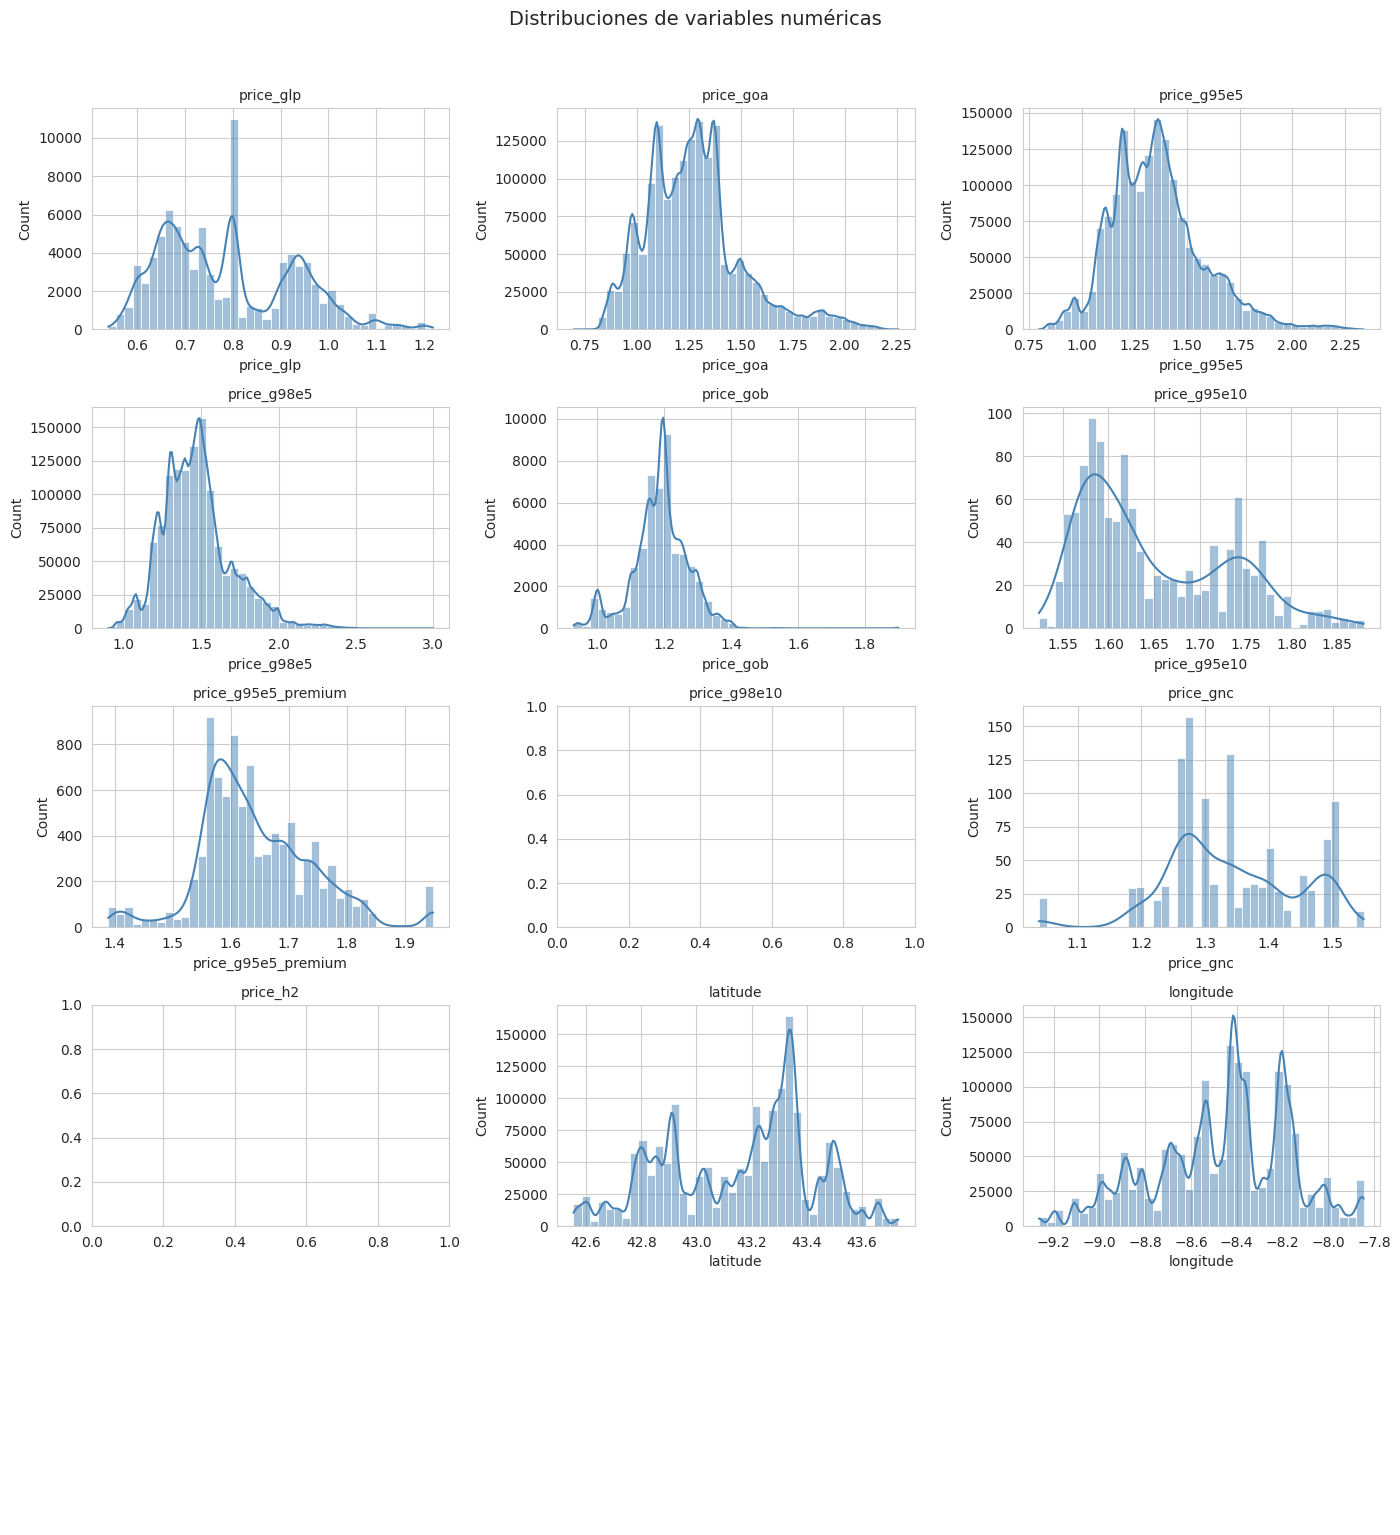

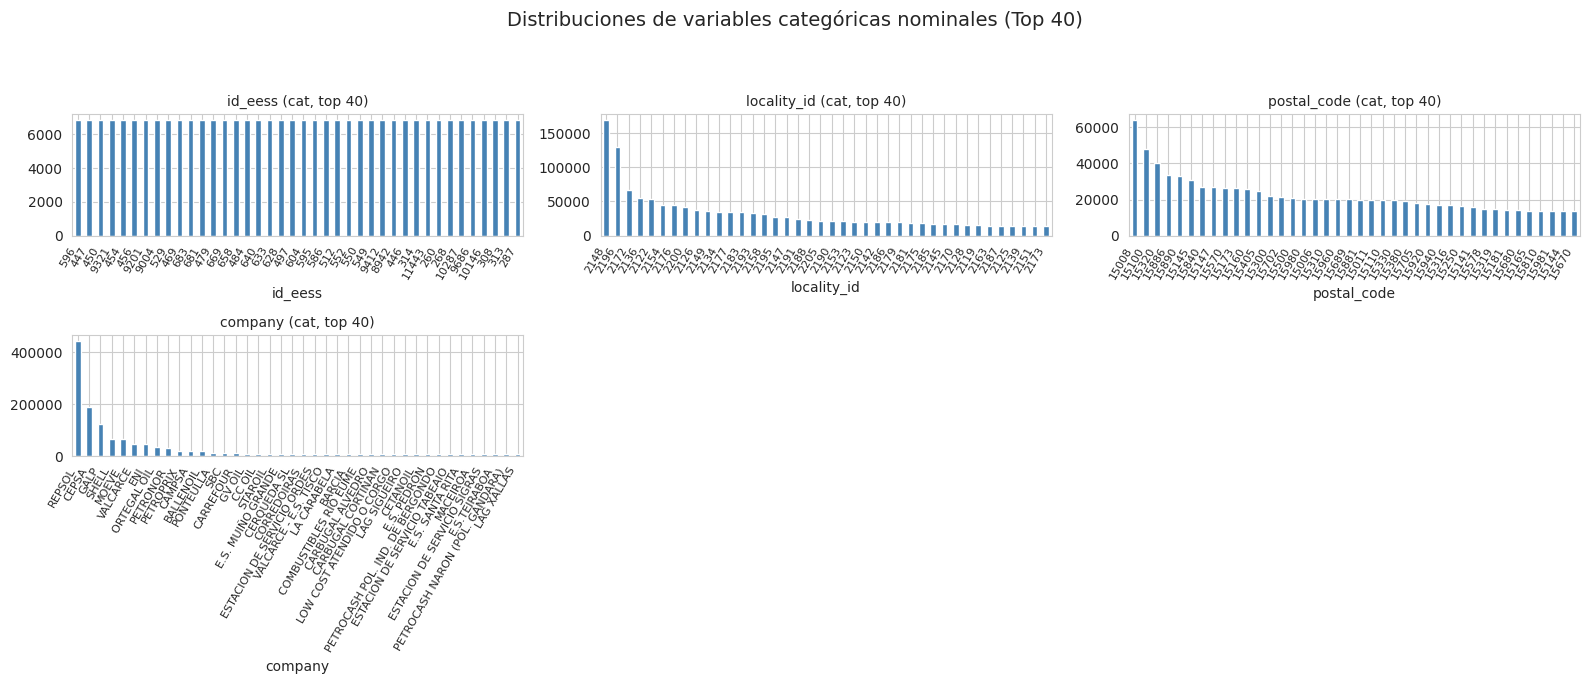

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

TOP_N_CAT = 40

def plot_distributions(df, num_cols=None, ord_cols=None, bin_cols=None, cat_cols=None, top_n_cat=TOP_N_CAT):
    sns.set_style("whitegrid")

    # === Numéricas ===
    if num_cols:
        pdf = df.select(*num_cols).toPandas()
        n = len(num_cols)
        nrows = (n // 3) + 1
        fig, axes = plt.subplots(nrows=nrows, ncols=3, figsize=(14, 3*nrows))
        axes = axes.flatten()
        for i, c in enumerate(num_cols):
            sns.histplot(pdf[c].dropna(), bins=40, kde=True, ax=axes[i], color="steelblue")
            axes[i].set_title(c, fontsize=10)
        for j in range(i+1, len(axes)):
            axes[j].axis("off")
        fig.suptitle("Distribuciones de variables numéricas", fontsize=14, y=1.02)
        plt.tight_layout()
        plt.show()

    # === Ordered ===
    if ord_cols:
        pdf = df.select(*ord_cols).toPandas()
        n = len(ord_cols)
        nrows = (n // 3) + 1
        fig, axes = plt.subplots(nrows=nrows, ncols=3, figsize=(14, 3*nrows))
        axes = axes.flatten()
        for i, c in enumerate(ord_cols):
            counts = pdf[c].value_counts(dropna=False).sort_index()
            counts.plot(kind="bar", ax=axes[i], color="steelblue")
            axes[i].set_title(f"{c} (ordered)", fontsize=10)
            axes[i].tick_params(axis="x", rotation=0)
        for j in range(i+1, len(axes)):
            axes[j].axis("off")
        fig.suptitle("Distribuciones de variables ordinales", fontsize=14, y=1.02)
        plt.tight_layout()
        plt.show()

    # === Binarias ===
    if bin_cols:
        pdf = df.select(*bin_cols).toPandas()
        n = len(bin_cols)
        nrows = (n // 3) + 1
        fig, axes = plt.subplots(nrows=nrows, ncols=3, figsize=(10, 3*nrows))
        axes = axes.flatten()
        for i, c in enumerate(bin_cols):
            counts = pdf[c].value_counts(dropna=False)
            counts.plot(kind="bar", ax=axes[i], color="steelblue")
            axes[i].set_title(f"{c} (bin)", fontsize=10)
            axes[i].tick_params(axis="x", rotation=0)
        for j in range(i+1, len(axes)):
            axes[j].axis("off")
        fig.suptitle("Distribuciones de variables binarias", fontsize=14, y=1.02)
        plt.tight_layout()
        plt.show()

    # === Categóricas (Top-N más frecuentes) ===
    if cat_cols:
        pdf = df.select(*cat_cols).toPandas()
        n = len(cat_cols)
        nrows = (n // 3) + 1
        fig, axes = plt.subplots(nrows=nrows, ncols=3, figsize=(16, 3.5*nrows))
        axes = axes.flatten()
        for i, c in enumerate(cat_cols):
            s = pdf[c]
            counts = s.value_counts(dropna=False).head(top_n_cat)
            counts.plot(kind="bar", ax=axes[i], color="steelblue")
            axes[i].set_title(f"{c} (cat, top {len(counts)})", fontsize=10)
            axes[i].tick_params(axis='x', rotation=60)
            # mejor alineación y espaciado
            for tick in axes[i].get_xticklabels():
                tick.set_ha('right')
                tick.set_fontsize(8)
        for j in range(i+1, len(axes)):
            axes[j].axis("off")
        fig.suptitle(f"Distribuciones de variables categóricas nominales (Top {top_n_cat})",
                     fontsize=14, y=1.02)
        plt.subplots_adjust(hspace=0.6, bottom=0.2)
        plt.tight_layout(rect=[0, 0.05, 1, 0.97])
        plt.show()

plot_distributions(df, num_cols, ord_cols, bin_cols, cat_cols)

### Matriz de Correlaciones Mixta

| Tipo de relación | Medida usada              | Qué indica                                           |
| ---------------- | ------------------------- | ---------------------------------------------------- |
| num ↔ num        | **Pearson**               | Correlación lineal clásica                           |
| cat ↔ cat        | **Cramer’s V**            | Asociación entre dos variables categóricas           |
| cat ↔ num        | **Correlation Ratio (η)** | Cuánto varía la variable numérica según la categoría |

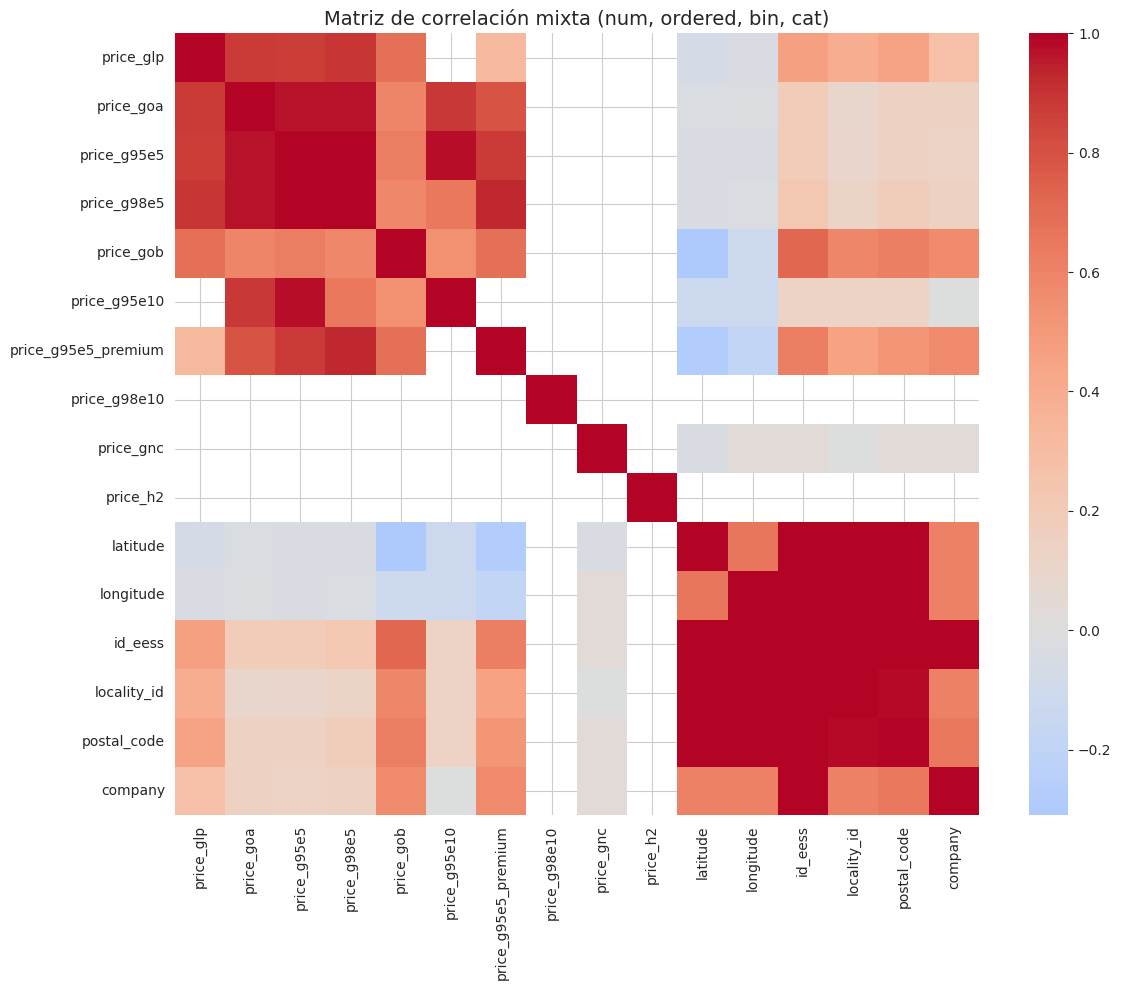

In [16]:
# === Correlación mixta robusta ===
import numpy as np
from scipy.stats import chi2_contingency, spearmanr, pearsonr
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def cramers_v(x, y):
    confusion = pd.crosstab(x, y)
    if confusion.size == 0 or confusion.shape[0] < 2 or confusion.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(confusion)[0]
    n = confusion.sum().sum()
    if n == 0:
        return np.nan
    phi2 = chi2 / n
    r, k = confusion.shape
    phi2corr = max(0, phi2 - ((k - 1)*(r - 1)) / max(n - 1, 1))
    rcorr = r - ((r - 1)**2) / max(n - 1, 1)
    kcorr = k - ((k - 1)**2) / max(n - 1, 1)
    denom = min((kcorr - 1), (rcorr - 1))
    if denom <= 0:
        return np.nan
    return np.sqrt(phi2corr / denom)

def correlation_ratio(categories, measurements):
    m = pd.Series(measurements).values
    c = pd.Series(categories).values
    mask = ~pd.isna(m) & ~pd.isna(c)
    m, c = m[mask], c[mask]
    if len(m) < 2:
        return np.nan
    fcat, _ = pd.factorize(c)
    cat_num = np.max(fcat) + 1
    y_avg_array = np.zeros(cat_num)
    n_array = np.zeros(cat_num)
    for i in range(cat_num):
        cat_measures = m[fcat == i]
        n_array[i] = len(cat_measures)
        y_avg_array[i] = np.mean(cat_measures) if n_array[i] > 0 else 0
    y_total_avg = np.sum(y_avg_array * n_array) / np.sum(n_array)
    numerator = np.sum(n_array * (y_avg_array - y_total_avg)**2)
    denominator = np.sum((m - y_total_avg)**2)
    return np.sqrt(numerator / denominator) if denominator > 0 else np.nan

def clean_pair(x, y):
    """Elimina NaN e infinitos en ambas columnas."""
    mask = (~pd.isna(x)) & (~pd.isna(y))
    return x[mask], y[mask]

def mixed_corr_matrix(df, num_cols, ord_cols, bin_cols, cat_cols):
    all_cols = list(dict.fromkeys(num_cols + ord_cols + bin_cols + cat_cols))
    pd_df = df.select(*all_cols).toPandas()

    # Helpers
    def is_num(c): return c in num_cols
    def is_ord(c): return c in ord_cols
    def is_bin(c): return c in bin_cols
    def is_cat(c): return c in cat_cols

    all_vars = all_cols
    corr_df = pd.DataFrame(index=all_vars, columns=all_vars, dtype=float)

    for i, v1 in enumerate(all_vars):
        for j, v2 in enumerate(all_vars):
            if v1 == v2:
                corr_df.loc[v1, v2] = 1.0
                continue

            x = pd_df[v1]
            y = pd_df[v2]

            # Limpieza de NaN
            x, y = clean_pair(x, y)
            if len(x) < 2:
                corr_df.loc[v1, v2] = np.nan
                continue

            # num–num
            if is_num(v1) and is_num(v2):
                corr = x.corr(y)
            # num–bin
            elif (is_num(v1) and is_bin(v2)) or (is_bin(v1) and is_num(v2)):
                try:
                    corr = pearsonr(x, y)[0]
                except Exception:
                    corr = np.nan
            # num–ordered → Spearman
            elif (is_num(v1) and is_ord(v2)) or (is_ord(v1) and is_num(v2)):
                corr = spearmanr(x, y, nan_policy='omit')[0]
            # ordered–ordered → Spearman
            elif is_ord(v1) and is_ord(v2):
                corr = spearmanr(x, y, nan_policy='omit')[0]
            # cat–cat (incluye bin/ord) → Cramer's V
            elif (is_cat(v1) or is_bin(v1) or is_ord(v1)) and (is_cat(v2) or is_bin(v2) or is_ord(v2)):
                corr = cramers_v(x, y)
            # cat–num / bin–num / ord–num → η
            else:
                if is_num(v1):
                    corr = correlation_ratio(y, x)
                else:
                    corr = correlation_ratio(x, y)

            corr_df.loc[v1, v2] = corr

    # Visualización
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_df.astype(float), cmap="coolwarm", center=0, annot=False)
    plt.title("Matriz de correlación mixta (num, ordered, bin, cat)", fontsize=14)
    plt.tight_layout()
    plt.show()

    return corr_df

corr_matrix = mixed_corr_matrix(df, num_cols, ord_cols, bin_cols, cat_cols)

### Test de Normalidad y Comparación de Medias

| **Test**                  | **Tipo de variables que compara**                   | **Qué evalúa**                                                                            | **Qué tipo de dato necesita / supuestos**                                                  |
| ------------------------- | --------------------------------------------------- | ----------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------ |
| **Pearson**               | **Numérica vs Numérica (lineal)**                   | Si existe una **relación lineal** entre dos variables numéricas continuas                 | Variables numéricas **con distribución normal** y relación lineal                          |
| **Spearman**              | **Numérica vs Numérica (monótona)**                 | Si existe una **relación monótona** (creciente o decreciente) entre dos variables         | Variables numéricas u **ordinales**, sin requerir normalidad ni linealidad                 |
| **t-test (Student)**      | **Numérica vs Binaria / dos grupos (normal)**       | Si las **medias de dos grupos** son significativamente distintas                          | Variable dependiente numérica **normal**, grupos independientes y con varianzas similares  |
| **Mann–Whitney U**        | **Numérica vs Binaria / dos grupos (no normal)**    | Igual que el t-test pero sin asumir normalidad (usa rangos)                               | Variable numérica continua o ordinal, **sin normalidad** requerida                         |
| **ANOVA**                 | **Categórica (≥3 grupos) vs Numérica (normal)**     | Si **al menos una media de grupo difiere** significativamente                             | Variable dependiente numérica **normal**, grupos independientes                            |
| **Kruskal–Wallis**        | **Categórica (≥3 grupos) vs Numérica (no normal)**  | Igual que ANOVA pero basado en **rangos** en lugar de medias                              | Variable numérica, **sin normalidad**, categorías independientes                           |
| **Chi-squared (χ²)**      | **Categórica vs Categórica**                        | Si existe **asociación entre dos variables categóricas** (independencia)                  | Datos **en frecuencias** (tablas de contingencia), valores no esperados <5 deben ser pocos |
| **Correlation Ratio (η)** | **Categórica vs Numérica (cualquier distribución)** | Cuánta **variabilidad de la variable numérica** se explica por la categórica (como un R²) | Variable dependiente numérica, categórica con ≥2 niveles                                   |


In [17]:
# === Tests de normalidad (solo numéricas continuas) ===
from scipy.stats import shapiro, normaltest
import pandas as pd

def normality_tests_numeric(df, numeric_cols, alpha=0.05):
    pd_df = df.select(*numeric_cols).toPandas()
    out = {}
    for c in numeric_cols:
        s = pd_df[c].dropna()
        if len(s) < 20:
            print(f"Skipping {c}: insufficient data ({len(s)} rows)")
            continue
        if len(s) <= 5000:
            print(f"Testing {c} with Shapiro (n={len(s)})")
            stat, p = shapiro(s)
            test = "Shapiro"
        else:
            print(f"Testing {c} with D’Agostino–Pearson (n={len(s)})")
            stat, p = normaltest(s)
            test = "D’Agostino–Pearson"
        out[c] = {"test": test, "p_value": p, "is_normal": p > alpha}
    return pd.DataFrame(out).T

normal_df = normality_tests_numeric(df, num_cols, alpha=0.05)
display(normal_df)

Testing price_glp with D’Agostino–Pearson (n=87979)
Testing price_goa with D’Agostino–Pearson (n=1618931)
Testing price_g95e5 with D’Agostino–Pearson (n=1603589)
Testing price_g98e5 with D’Agostino–Pearson (n=1251762)
Testing price_gob with D’Agostino–Pearson (n=50483)
Testing price_g95e10 with Shapiro (n=1150)
Testing price_g95e5_premium with D’Agostino–Pearson (n=9137)
Skipping price_g98e10: insufficient data (0 rows)
Testing price_gnc with Shapiro (n=1118)
Skipping price_h2: insufficient data (0 rows)
Testing latitude with D’Agostino–Pearson (n=1628611)
Testing longitude with D’Agostino–Pearson (n=1628611)


,test,p_value,is_normal
price_glp,D’Agostino–Pearson,0.0,False
price_goa,D’Agostino–Pearson,0.0,False
price_g95e5,D’Agostino–Pearson,0.0,False
price_g98e5,D’Agostino–Pearson,0.0,False
price_gob,D’Agostino–Pearson,0.0,False
price_g95e10,Shapiro,0.0,False
price_g95e5_premium,D’Agostino–Pearson,0.0,False
price_gnc,Shapiro,0.0,False
latitude,D’Agostino–Pearson,0.0,False
longitude,D’Agostino–Pearson,0.0,False


In [18]:
# === Significancia vs objetivos ===
from scipy.stats import spearmanr, pearsonr, f_oneway, kruskal
import numpy as np

def significance_vs_targets(df, col_info, goal_vars, normal_df, alpha=0.05):
    cols_needed = list(dict.fromkeys(
        col_info["num"] + col_info["cat"] + col_info.get("bin", []) + col_info.get("ordered", []) + goal_vars
    ))
    pd_df = df.select(*[c for c in cols_needed if c in df.columns]).toPandas()

    results = []
    num_cols = [c for c in col_info["num"] if c in pd_df.columns]
    cat_like_cols = [c for c in (col_info["cat"] + col_info.get("bin", []) + col_info.get("ordered", [])) if c in pd_df.columns]

    for target in goal_vars:
        if target not in pd_df.columns:
            continue

        # num–num (incluye cíclicas en num_cols) → Pearson/Spearman según normalidad
        for feature in num_cols:
            if feature == target:
                continue
            pair = pd_df[[feature, target]].dropna()
            if pair.empty:
                continue
            normal_target = normal_df.loc[target, "is_normal"] if target in normal_df.index else False
            normal_feat   = normal_df.loc[feature, "is_normal"] if feature in normal_df.index else False
            if normal_target and normal_feat:
                stat, p = pearsonr(pair[feature], pair[target])
                test = "Pearson"
            else:
                stat, p = spearmanr(pair[feature], pair[target])
                test = "Spearman"
            results.append((target, feature, test, p, stat))

        # cat/bin/ordered ↔ num (target) → ANOVA o Kruskal–Wallis
        for feature in cat_like_cols:
            if feature == target or feature not in pd_df.columns:
                continue
            grp = pd_df[[feature, target]].dropna().groupby(feature)[target].apply(list)
            if len(grp) < 2:
                continue
            normal_target = normal_df.loc[target, "is_normal"] if target in normal_df.index else False
            if normal_target:
                stat, p = f_oneway(*grp)
                test = "ANOVA"
            else:
                stat, p = kruskal(*grp)
                test = "Kruskal–Wallis"
            results.append((target, feature, test, p, stat))

    res_df = pd.DataFrame(results, columns=["target","feature","test","p_value","statistic"])
    res_df["significant"] = res_df["p_value"] < alpha
    return res_df

results_df = significance_vs_targets(df, COL_INFO, GOAL_VARIABLES, normal_df, alpha=0.05)
display(results_df.sort_values(["target","p_value"]))

,target,feature,test,p_value,statistic,significant
11,price_g95e5,price_glp,Spearman,0.000000e+00,0.903438,True
12,price_g95e5,price_goa,Spearman,0.000000e+00,0.974108,True
13,price_g95e5,price_g98e5,Spearman,0.000000e+00,0.993892,True
14,price_g95e5,price_gob,Spearman,0.000000e+00,0.635317,True
15,price_g95e5,price_g95e10,Spearman,0.000000e+00,0.955721,True
16,price_g95e5,price_g95e5_premium,Spearman,0.000000e+00,0.902363,True
17,price_g95e5,latitude,Spearman,0.000000e+00,-0.031278,True
19,price_g95e5,id_eess,Kruskal–Wallis,0.000000e+00,61287.675625,True
20,price_g95e5,locality_id,Kruskal–Wallis,0.000000e+00,14901.654907,True
21,price_g95e5,postal_code,Kruskal–Wallis,0.000000e+00,30794.407561,True


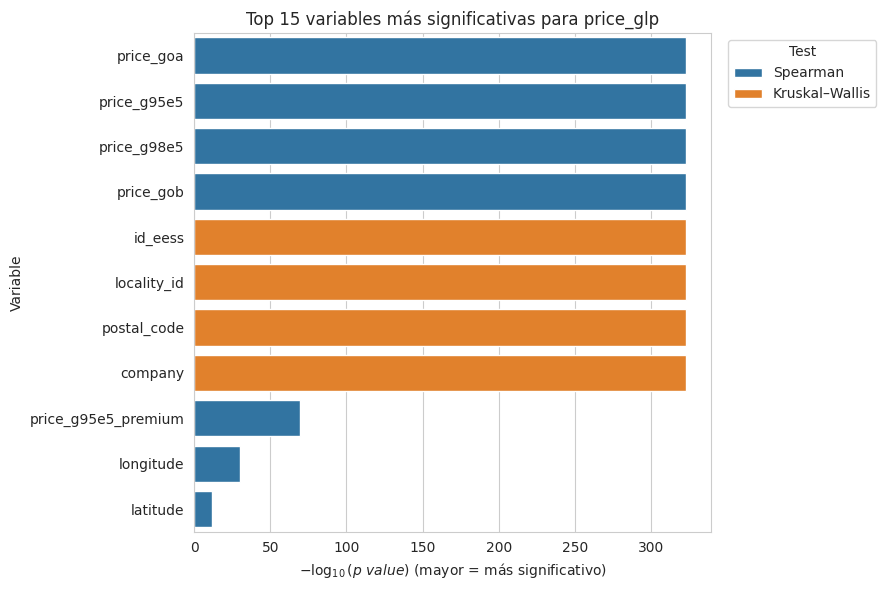

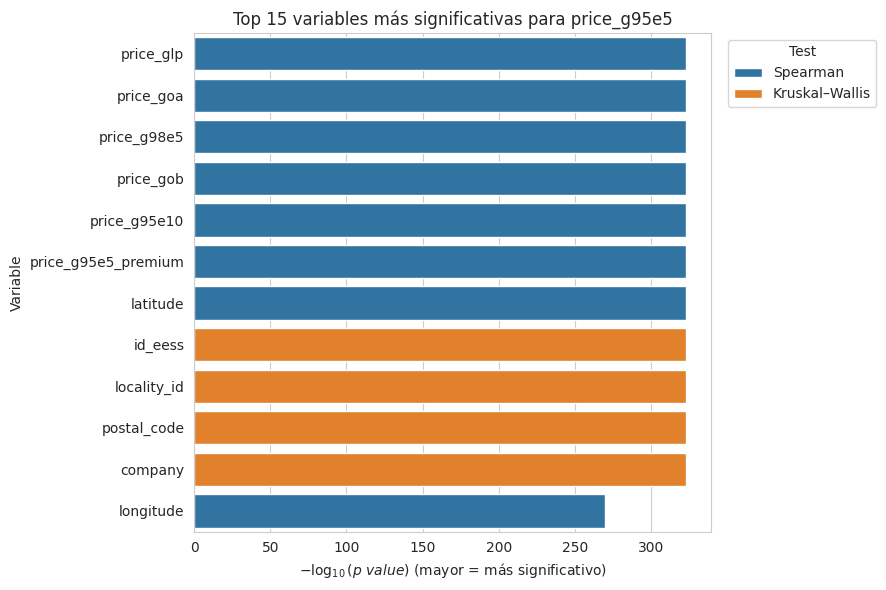

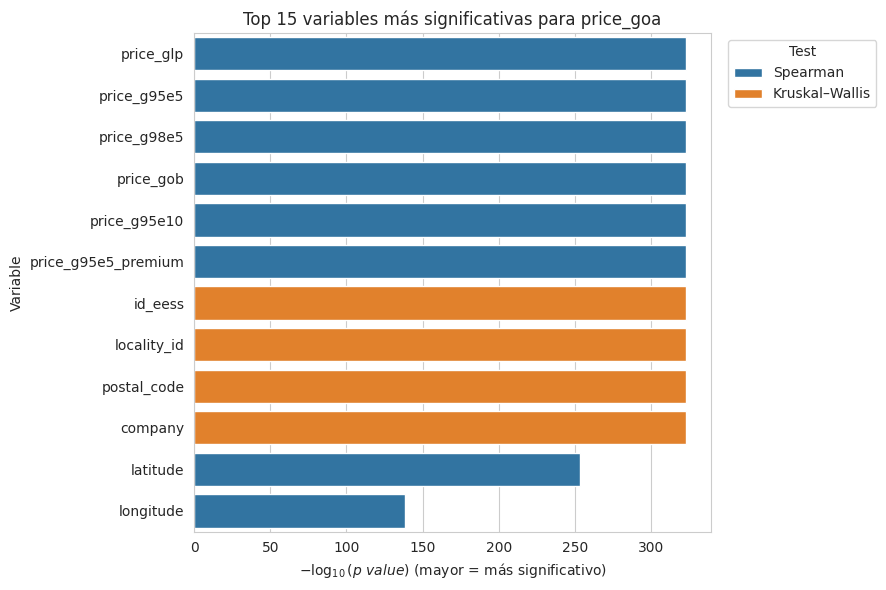

In [19]:
# Visualización: 15 variables más significativas por variable objetivo

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# === Top-15 por objetivo ===
results_df = results_df.copy()
results_df["importance"] = -np.log10(results_df["p_value"].replace(0, np.nextafter(0, 1)))

for target in GOAL_VARIABLES:
    sub = results_df[results_df["target"] == target]
    if sub.empty:
        continue
    top15 = sub.sort_values("p_value").head(50)
    plt.figure(figsize=(9,6))
    sns.barplot(data=top15, y="feature", x="importance", hue="test", dodge=False)
    plt.title(f"Top 15 variables más significativas para {target}")
    plt.xlabel(r"$-\log_{10}(p\ value)$ (mayor = más significativo)")
    plt.ylabel("Variable")
    plt.legend(title="Test", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## Feature Engineering y Análisis Estadístico Descriptivo Avanzado

### Feature Engineering

In [3]:
# Creación y Transformación cíclica de variables temporales

import math
from pyspark.sql import functions as F

df_fe = (
    df
    .withColumn("day_of_week", F.dayofweek("date"))  # 1..7
    .withColumn("month", F.month("date"))
    .withColumn("year", F.year("date"))
    .withColumn("day_of_year", F.dayofyear("date"))
    .withColumn("week_of_year", F.weekofyear("date"))
    .withColumn("is_weekend", F.when(F.col("day_of_week").isin(1,7), 1).otherwise(0))  # 1=Dom,7=Sáb en Spark
    .withColumn("is_24h", (col("schedule") == "L-D: 24H").cast("int"))

    # --- Transformaciones cíclicas ---
    # Día de la semana (7 días)
    .withColumn("day_of_week_sin", F.sin(2 * math.pi * F.col("day_of_week") / 7))
    .withColumn("day_of_week_cos", F.cos(2 * math.pi * F.col("day_of_week") / 7))

    # Mes (12 meses)
    .withColumn("month_sin", F.sin(2 * math.pi * F.col("month") / 12))
    .withColumn("month_cos", F.cos(2 * math.pi * F.col("month") / 12))

    # Semana del año (52 semanas)
    .withColumn("week_of_year_sin", F.sin(2 * math.pi * F.col("week_of_year") / 52))
    .withColumn("week_of_year_cos", F.cos(2 * math.pi * F.col("week_of_year") / 52))

    # Día del año (365 días)
    .withColumn("day_of_year_sin", F.sin(2 * math.pi * F.col("day_of_year") / 365))
    .withColumn("day_of_year_cos", F.cos(2 * math.pi * F.col("day_of_year") / 365))
)

df_fe.select(
    "id_eess", "date",
    "day_of_week", "day_of_week_sin", "day_of_week_cos",
    "month", "month_sin", "month_cos",
    "week_of_year", "week_of_year_sin", "week_of_year_cos",
    "day_of_year", "day_of_year_sin", "day_of_year_cos",
    "is_weekend"
).show(5, truncate=False)


+-------+----------+-----------+-------------------+--------------------+-----+-------------------+------------------+------------+-------------------+-----------------+-----------+--------------------+------------------+----------+
|id_eess|date      |day_of_week|day_of_week_sin    |day_of_week_cos     |month|month_sin          |month_cos         |week_of_year|week_of_year_sin   |week_of_year_cos |day_of_year|day_of_year_sin     |day_of_year_cos   |is_weekend|
+-------+----------+-----------+-------------------+--------------------+-----+-------------------+------------------+------------+-------------------+-----------------+-----------+--------------------+------------------+----------+
|249    |2007-01-01|2          |0.9749279121818236 |-0.22252093395631434|1    |0.49999999999999994|0.8660254037844387|1           |0.12053668025532305|0.992708874098054|1          |0.017213356155834685|0.9998518392091162|0         |
|249    |2007-01-02|3          |0.43388373911755823|-0.9009688679024

In [4]:
from pyspark.sql import functions as F
import math

# Núcleos principales de la provincia (lat, lon)
NUCLEOS = {
    "coruna":   (43.376461, -8.398824),  # punto central de A Coruña
    "santiago": (42.88052,  -8.54569),
    "ferrol":   (43.4849,   -8.2307),
    "carballo": (43.2131,   -8.691),
    "naron":    (43.501,    -8.189),
    "betanzos": (43.2808,   -8.2139),
    "ribeira":  (42.5542,   -8.991),
    "noia":     (42.7833,   -8.887),
    "ordes":    (43.0769,   -8.4097),
    "boiro":    (42.6469,   -8.883)
}

# --- UDF Haversine genérica ---
@F.udf("double")
def haversine_udf(lat, lon, lat_ref, lon_ref):
    if lat is None or lon is None:
        return None
    R = 6371.0
    dlat = math.radians(lat - lat_ref)
    dlon = math.radians(lon - lon_ref)
    a = (math.sin(dlat / 2) ** 2 +
         math.cos(math.radians(lat_ref)) *
         math.cos(math.radians(lat)) *
         math.sin(dlon / 2) ** 2)
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

# --- Clustering geográfico ---
df_geo = df_fe.dropna(subset=["latitude", "longitude"]).select("latitude", "longitude").distinct()
geo_assembler = VectorAssembler(inputCols=["latitude", "longitude"], outputCol="geo_vec")
geo_kmeans = KMeans(k=10, seed=42, featuresCol="geo_vec", predictionCol="geo_cluster")
geo_pipeline = Pipeline(stages=[geo_assembler, geo_kmeans])
geo_model = geo_pipeline.fit(df_geo)
df_fe = geo_model.transform(df_fe)

# --- Distancias geográficas ---
for name, (lat_ref, lon_ref) in NUCLEOS.items():
    df_fe = df_fe.withColumn(f"dist_{name}_km",
                       haversine_udf(col("latitude"), col("longitude"),
                                     F.lit(lat_ref), F.lit(lon_ref)))

# --- Distancia mínima a núcleo urbano ---
dist_cols = [f"dist_{n}_km" for n in NUCLEOS.keys()]
df_fe = df_fe.withColumn("min_dist_urbana_km", F.least(*[col(c) for c in dist_cols]))

# --- Comprobación ---
df_fe.select("id_eess", "latitude", "longitude", "geo_cluster", "min_dist_urbana_km", "dist_coruna_km", "dist_santiago_km", "dist_ferrol_km", "dist_carballo_km", "dist_naron_km", "dist_betanzos_km", "dist_ribeira_km", "dist_noia_km", "dist_ordes_km", "dist_boiro_km").show(5, truncate=False)

+-------+---------+---------+-----------+------------------+------------------+-----------------+-----------------+-----------------+-----------------+------------------+-----------------+------------------+------------------+------------------+
|id_eess|latitude |longitude|geo_cluster|min_dist_urbana_km|dist_coruna_km    |dist_santiago_km |dist_ferrol_km   |dist_carballo_km |dist_naron_km    |dist_betanzos_km  |dist_ribeira_km  |dist_noia_km      |dist_ordes_km     |dist_boiro_km     |
+-------+---------+---------+-----------+------------------+------------------+-----------------+-----------------+-----------------+-----------------+------------------+-----------------+------------------+------------------+------------------+
|249    |42.811139|-8.545361|4          |7.714861832070907 |63.977104471965156|7.714861832070907|79.14825857200353|46.23799404210512|81.97456096699445|58.760747834943594|46.29465777738937|28.045905584031654|31.546968589415044|33.077089445560006|
|249    |42.8111

In [5]:
# Construcción de dataset único con lags/medias móviles para múltiples combustibles

from pyspark.sql import Window
from pyspark.sql.functions import col, unix_timestamp, lag, mean as F_mean, stddev_samp

def add_temporal_features(base_df, target_cols):
    """
    Añade columnas de lags, medias móviles y desviaciones estándar
    para todas las variables de target especificadas en target_cols.
    Mantiene todas las columnas originales (no hace selección).
    """

    df_t = base_df.withColumn("ts", unix_timestamp(col("date")).cast("long"))
    w_sta = Window.partitionBy("id_eess").orderBy(col("ts"))
    w_sta_7d  = w_sta.rangeBetween(-7 * 86400, 0)
    w_sta_14d = w_sta.rangeBetween(-14 * 86400, 0)

    for target_col in target_cols:
        if target_col not in df_t.columns:
            continue

        # Lags del target (1, 7, 14 días)
        df_t = (
            df_t
            .withColumn(f"{target_col}_lag_1d",  lag(target_col, 1).over(w_sta))
            .withColumn(f"{target_col}_lag_7d",  lag(target_col, 7).over(w_sta))
            .withColumn(f"{target_col}_lag_14d", lag(target_col,14).over(w_sta))
        )

        # Medias móviles y desviaciones (sin fuga)
        df_t = (
            df_t
            .withColumn(f"{target_col}_ma_7d_raw",  F_mean(target_col).over(w_sta_7d))
            .withColumn(f"{target_col}_ma_14d_raw", F_mean(target_col).over(w_sta_14d))
            .withColumn(f"{target_col}_std_14d_raw", stddev_samp(target_col).over(w_sta_14d))
            .withColumn(f"{target_col}_ma_7d",  lag(f"{target_col}_ma_7d_raw", 1).over(w_sta))
            .withColumn(f"{target_col}_ma_14d", lag(f"{target_col}_ma_14d_raw", 1).over(w_sta))
            .withColumn(f"{target_col}_std_14d", lag(f"{target_col}_std_14d_raw", 1).over(w_sta))
            .drop(f"{target_col}_ma_7d_raw", f"{target_col}_ma_14d_raw", f"{target_col}_std_14d_raw")
        )

    return df_t.drop("ts")

target_cols = ["price_goa", "price_g95e5", "price_glp"]
df_full = add_temporal_features(df_fe, target_cols)

print("Filas totales:", df_full.count())
df_full.select(
    "date", "id_eess", "price_goa_lag_1d", "price_g95e5_ma_7d", "price_glp_std_14d"
).show(5, truncate=False)


Filas totales: 1628611


+----------+-------+----------------+------------------+-----------------+
|date      |id_eess|price_goa_lag_1d|price_g95e5_ma_7d |price_glp_std_14d|
+----------+-------+----------------+------------------+-----------------+
|2007-01-09|296    |NULL            |NULL              |NULL             |
|2007-01-10|296    |0.912           |0.974             |NULL             |
|2007-01-11|296    |0.902           |0.971             |NULL             |
|2007-01-12|296    |0.902           |0.9700000000000001|NULL             |
|2007-01-13|296    |0.902           |0.9695            |NULL             |
+----------+-------+----------------+------------------+-----------------+
only showing top 5 rows


In [6]:
import os
if not os.path.exists("data/df_full.csv"):
    df_full.toPandas().to_csv("data/df_full.csv", index=False)

25/10/22 17:04:58 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


### Carga de datos con feature engineered variables

In [2]:
df_full = (
    spark.read.option("header", "true")
    .option("inferSchema", "true")
    .option("delimiter", ",")
    .csv("data/df_full.csv")
)

In [9]:
df_full.printSchema()

root
 |-- id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- price_glp: double (nullable = true)
 |-- price_goa: double (nullable = true)
 |-- station_id: integer (nullable = true)
 |-- price_g95e5: double (nullable = true)
 |-- price_g98e5: double (nullable = true)
 |-- price_gob: double (nullable = true)
 |-- price_g95e10: double (nullable = true)
 |-- price_g95e5_premium: double (nullable = true)
 |-- price_g98e10: double (nullable = true)
 |-- price_gnc: double (nullable = true)
 |-- price_h2: double (nullable = true)
 |-- id_eess: integer (nullable = true)
 |-- company: string (nullable = true)
 |-- address: string (nullable = true)
 |-- schedule: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- locality_id: integer (nullable = true)
 |-- postal_code: integer (nullable = true)
 |-- province_id: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- id_prov: integer (nullable = true)
 |-- da

### Análisis Estadístico Avanzado

In [21]:
# Diccionario actualizado de tipos de variables (tras feature engineering completo)
COL_INFO = {
    "num": [
        # --- precios base ---
        "price_glp", "price_goa", "price_g95e5", "price_g98e5",
        "price_gob", "price_g95e10", "price_g95e5_premium",
        "price_g98e10", "price_gnc", "price_h2",

        # --- coordenadas y distancias ---
        "latitude", "longitude",
        "dist_coruna_km", "dist_santiago_km", "dist_ferrol_km",
        "dist_carballo_km", "dist_naron_km", "dist_betanzos_km",
        "dist_ribeira_km", "dist_noia_km", "dist_ordes_km",
        "dist_boiro_km", "min_dist_urbana_km",

        # --- variables cíclicas (seno y coseno) ---
        "day_of_week_sin", "day_of_week_cos",
        "month_sin", "month_cos",
        "week_of_year_sin", "week_of_year_cos",
        "day_of_year_sin", "day_of_year_cos",

        # --- variables temporales generadas para cada combustible ---
        # GOA
        "price_goa_lag_1d", "price_goa_lag_7d", "price_goa_lag_14d",
        "price_goa_ma_7d", "price_goa_ma_14d", "price_goa_std_14d",

        # G95E5
        "price_g95e5_lag_1d", "price_g95e5_lag_7d", "price_g95e5_lag_14d",
        "price_g95e5_ma_7d", "price_g95e5_ma_14d", "price_g95e5_std_14d",

        # GLP
        "price_glp_lag_1d", "price_glp_lag_7d", "price_glp_lag_14d",
        "price_glp_ma_7d", "price_glp_ma_14d", "price_glp_std_14d"
    ],

    "cat": [
        # --- categóricas nominales ---
        "id_eess", "locality_id", "postal_code",
        "geo_cluster", "company"
    ],

    "bin": [
        # --- binarias ---
        "is_weekend", "is_24h"
    ],

    "ordered": [
        # --- categóricas ordinales temporales (no cíclicas) ---
        "day_of_week", "month", "year", "day_of_year", "week_of_year"
    ],

    "date": [
        # --- variable temporal principal ---
        "date"
    ],

    "drop": [
        # --- identificadores, strings no estructurados, duplicados o vectores internos ---
        "id", "station_id", "address", "schedule",
        "province_id", "id_prov", "name", "geo_vec"
    ]
}

num_cols = [c for c in COL_INFO["num"] if c in df_full.columns]
cat_cols = [c for c in COL_INFO["cat"] if c in df_full.columns]
bin_cols = [c for c in COL_INFO["bin"] if c in df_full.columns]
ordered_cols = [c for c in COL_INFO["ordered"] if c in df_full.columns]
date_cols = [c for c in COL_INFO["date"] if c in df_full.columns]
drop_cols = [c for c in COL_INFO["drop"] if c in df_full.columns]

# --- Visualización resumida ---
for k, v in COL_INFO.items():
    print(f"{k.upper():8} ({len(v)}): {v}")


NUM      (49): ['price_glp', 'price_goa', 'price_g95e5', 'price_g98e5', 'price_gob', 'price_g95e10', 'price_g95e5_premium', 'price_g98e10', 'price_gnc', 'price_h2', 'latitude', 'longitude', 'dist_coruna_km', 'dist_santiago_km', 'dist_ferrol_km', 'dist_carballo_km', 'dist_naron_km', 'dist_betanzos_km', 'dist_ribeira_km', 'dist_noia_km', 'dist_ordes_km', 'dist_boiro_km', 'min_dist_urbana_km', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'week_of_year_sin', 'week_of_year_cos', 'day_of_year_sin', 'day_of_year_cos', 'price_goa_lag_1d', 'price_goa_lag_7d', 'price_goa_lag_14d', 'price_goa_ma_7d', 'price_goa_ma_14d', 'price_goa_std_14d', 'price_g95e5_lag_1d', 'price_g95e5_lag_7d', 'price_g95e5_lag_14d', 'price_g95e5_ma_7d', 'price_g95e5_ma_14d', 'price_g95e5_std_14d', 'price_glp_lag_1d', 'price_glp_lag_7d', 'price_glp_lag_14d', 'price_glp_ma_7d', 'price_glp_ma_14d', 'price_glp_std_14d']
CAT      (5): ['id_eess', 'locality_id', 'postal_code', 'geo_cluster', 'company']
BIN    

In [22]:
# === Nulos y cardinalidad ===

nulls_df = nulls_and_cardinality(df_full)
nulls_df.orderBy(F.desc("null_pct")).show(df_full.columns.__len__(), truncate=False)

+-------------------+------+----------+--------------+--------+
|column             |dtype |null_count|distinct_count|null_pct|
+-------------------+------+----------+--------------+--------+
|price_g98e10       |string|1628611   |1             |100.0   |
|price_h2           |string|1628611   |1             |100.0   |
|price_g95e10       |double|1627461   |151           |99.93   |
|price_gnc          |double|1627493   |26            |99.93   |
|price_g95e5_premium|double|1619474   |249           |99.44   |
|price_gob          |double|1578128   |323           |96.9    |
|price_glp_lag_14d  |double|1541094   |288           |94.63   |
|price_glp_lag_7d   |double|1540863   |288           |94.61   |
|price_glp          |double|1540632   |288           |94.6    |
|price_glp_lag_1d   |double|1540665   |288           |94.6    |
|price_glp_std_14d  |double|1540587   |5467          |94.6    |
|price_glp_ma_7d    |double|1540543   |4152          |94.59   |
|price_glp_ma_14d   |double|1540485   |8

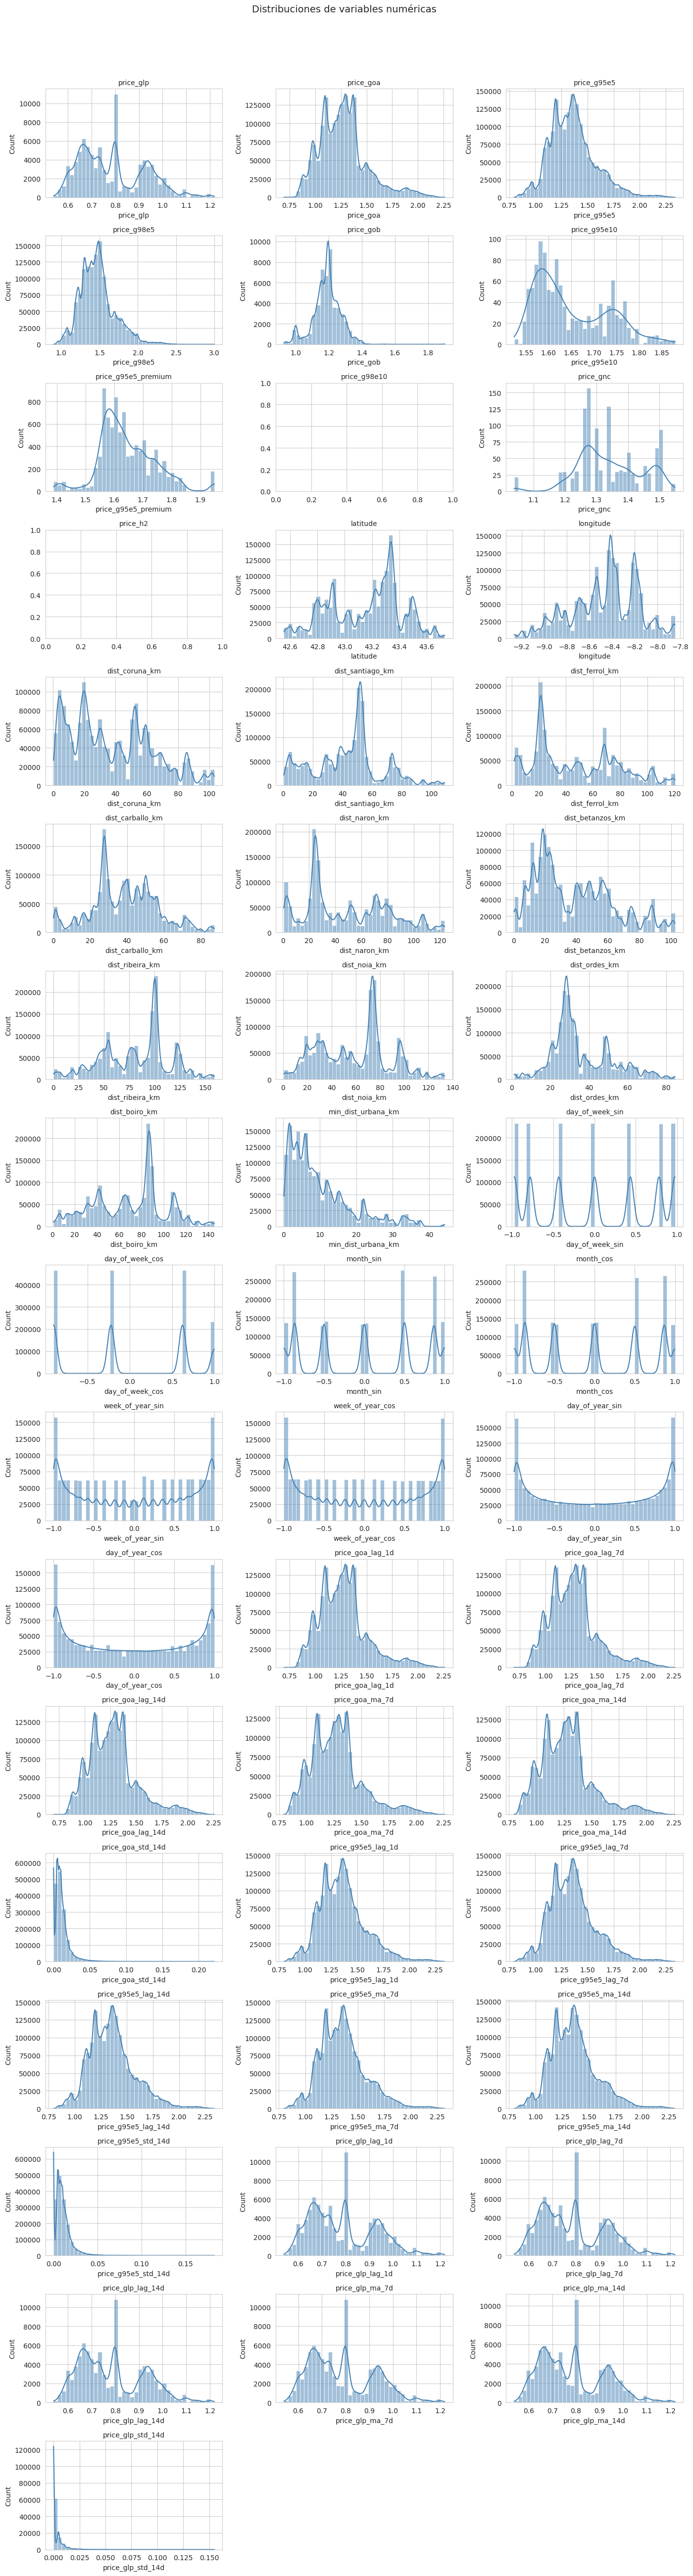

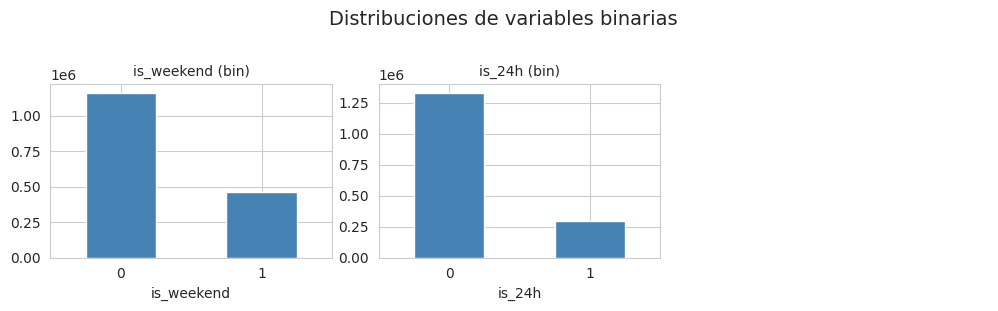

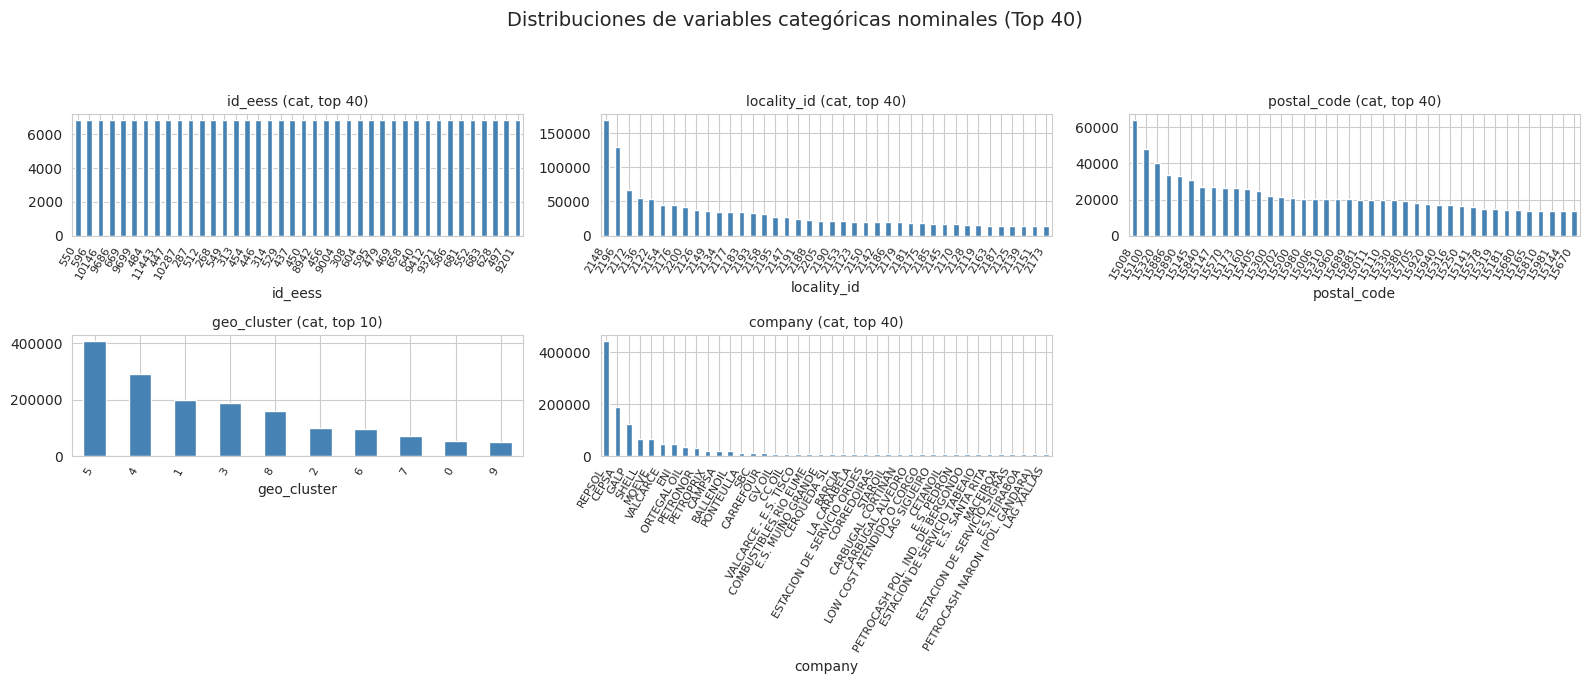

In [23]:
# === Visualización de distribuciones ===

plot_distributions(df_full, num_cols, ord_cols, bin_cols, cat_cols)

/tmp/ipykernel_161285/1635009466.py:85: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr = pearsonr(x, y)[0]
/tmp/ipykernel_161285/1635009466.py:85: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr = pearsonr(x, y)[0]


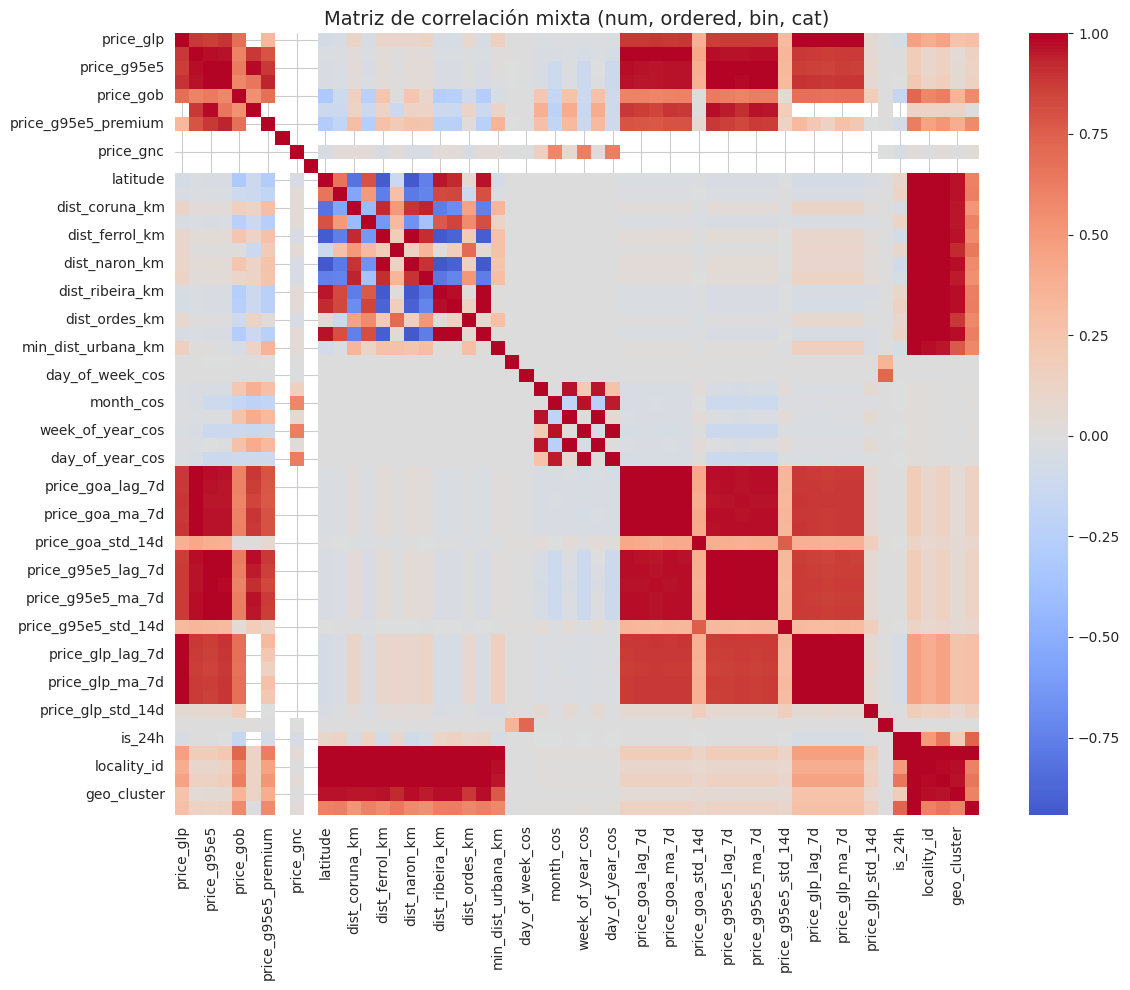

In [24]:
# === Correlación mixta robusta ===

corr_matrix = mixed_corr_matrix(df_full, num_cols, ord_cols, bin_cols, cat_cols)

In [25]:
# === Tests de normalidad (solo numéricas continuas) ===

normal_df = normality_tests_numeric(df_full, num_cols, alpha=0.05)
display(normal_df)

Testing price_glp with D’Agostino–Pearson (n=87979)
Testing price_goa with D’Agostino–Pearson (n=1618931)
Testing price_g95e5 with D’Agostino–Pearson (n=1603589)
Testing price_g98e5 with D’Agostino–Pearson (n=1251762)
Testing price_gob with D’Agostino–Pearson (n=50483)
Testing price_g95e10 with Shapiro (n=1150)
Testing price_g95e5_premium with D’Agostino–Pearson (n=9137)
Skipping price_g98e10: insufficient data (0 rows)
Testing price_gnc with Shapiro (n=1118)
Skipping price_h2: insufficient data (0 rows)
Testing latitude with D’Agostino–Pearson (n=1628611)
Testing longitude with D’Agostino–Pearson (n=1628611)
Testing dist_coruna_km with D’Agostino–Pearson (n=1628611)
Testing dist_santiago_km with D’Agostino–Pearson (n=1628611)
Testing dist_ferrol_km with D’Agostino–Pearson (n=1628611)
Testing dist_carballo_km with D’Agostino–Pearson (n=1628611)
Testing dist_naron_km with D’Agostino–Pearson (n=1628611)
Testing dist_betanzos_km with D’Agostino–Pearson (n=1628611)
Testing dist_ribeira_km 

,test,p_value,is_normal
price_glp,D’Agostino–Pearson,0.0,False
price_goa,D’Agostino–Pearson,0.0,False
price_g95e5,D’Agostino–Pearson,0.0,False
price_g98e5,D’Agostino–Pearson,0.0,False
price_gob,D’Agostino–Pearson,0.0,False
price_g95e10,Shapiro,0.0,False
price_g95e5_premium,D’Agostino–Pearson,0.0,False
price_gnc,Shapiro,0.0,False
latitude,D’Agostino–Pearson,0.0,False
longitude,D’Agostino–Pearson,0.0,False


In [26]:
# === Significancia vs objetivos ===

results_df = significance_vs_targets(df_full, COL_INFO, GOAL_VARIABLES, normal_df, alpha=0.05)
display(results_df.sort_values(["target","p_value"]))

,target,feature,test,p_value,statistic,significant
56,price_g95e5,price_glp,Spearman,0.000000,0.903438,True
57,price_g95e5,price_goa,Spearman,0.000000,0.974108,True
58,price_g95e5,price_g98e5,Spearman,0.000000,0.993892,True
59,price_g95e5,price_gob,Spearman,0.000000,0.635317,True
60,price_g95e5,price_g95e10,Spearman,0.000000,0.955721,True
...,...,...,...,...,...,...
132,price_goa,day_of_week_sin,Spearman,0.000123,-0.003018,True
165,price_goa,day_of_week,Kruskal–Wallis,0.007993,17.376902,True
164,price_goa,is_24h,Kruskal–Wallis,0.014970,5.919971,True
133,price_goa,day_of_week_cos,Spearman,0.716716,-0.000285,False


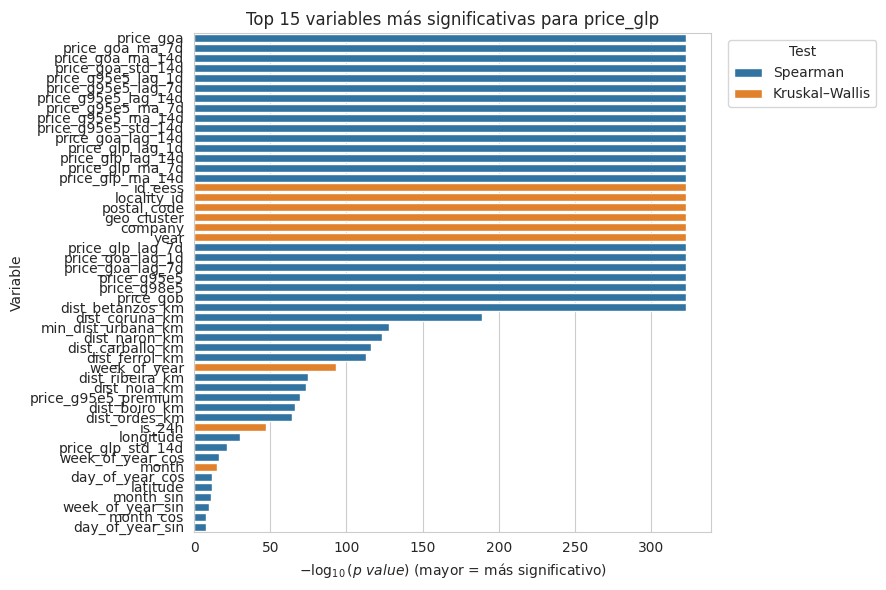

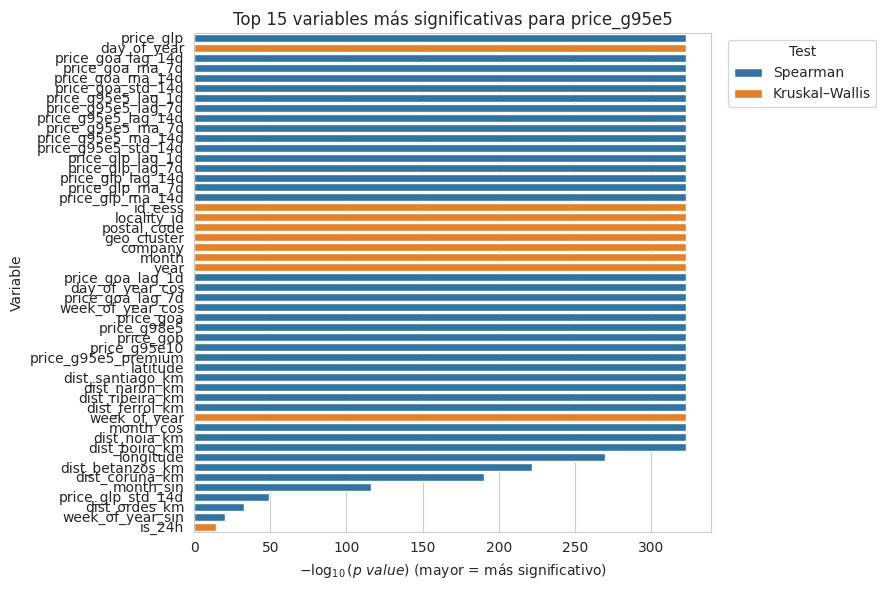

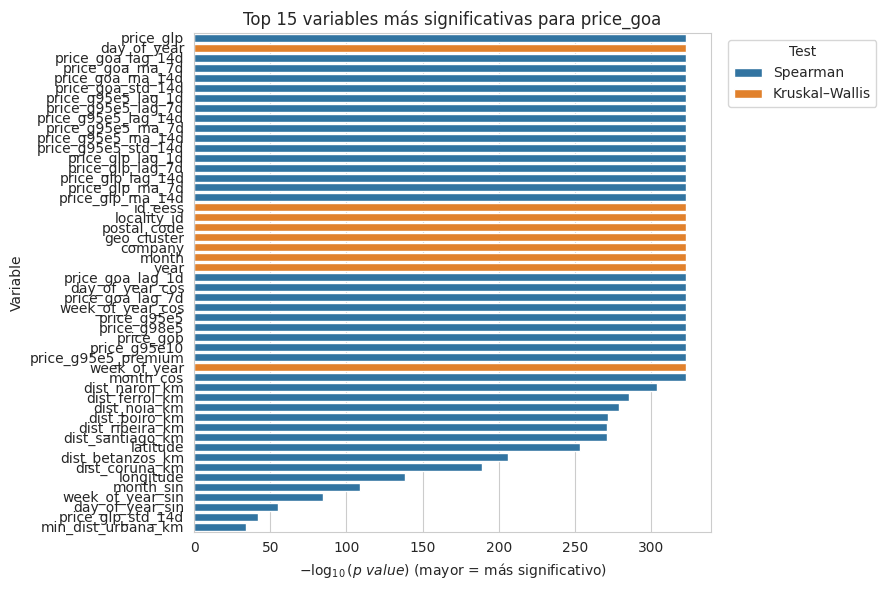

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# === Top-15 por objetivo ===
results_df = results_df.copy()
results_df["importance"] = -np.log10(results_df["p_value"].replace(0, np.nextafter(0, 1)))

for target in GOAL_VARIABLES:
    sub = results_df[results_df["target"] == target]
    if sub.empty:
        continue
    top15 = sub.sort_values("p_value").head(50)
    plt.figure(figsize=(9,6))
    sns.barplot(data=top15, y="feature", x="importance", hue="test", dodge=False)
    plt.title(f"Top 15 variables más significativas para {target}")
    plt.xlabel(r"$-\log_{10}(p\ value)$ (mayor = más significativo)")
    plt.ylabel("Variable")
    plt.legend(title="Test", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## Feature Selection y Preprocesado para entrenamiento

Atendiendo al conteo de nulos y la cardinalidad, eliminamos aquellas variables que tienen únicamente 1 valor y aquellas que tienen cerca del 100% de nulos.

Las columnas de glp las dejamos para incluirlas en su propio dataset.

In [3]:
# Diccionario actualizado de tipos de variables (tras feature engineering completo)
COL_INFO = {
    "num": [
        # --- precios base ---
        "price_glp", "price_goa", "price_g95e5"

        # --- coordenadas y distancias ---
        "latitude", "longitude",
        "dist_coruna_km", "dist_santiago_km", "dist_ferrol_km",
        "dist_carballo_km", "dist_naron_km", "dist_betanzos_km",
        "dist_ribeira_km", "dist_noia_km", "dist_ordes_km",
        "dist_boiro_km", "min_dist_urbana_km",

        # --- variables cíclicas (seno y coseno) ---
        "day_of_week_sin", "day_of_week_cos",
        "month_sin", "month_cos",
        "week_of_year_sin", "week_of_year_cos",
        "day_of_year_sin", "day_of_year_cos",

        # --- variables temporales generadas para cada combustible ---
        # GOA
        "price_goa_lag_1d", "price_goa_lag_7d", "price_goa_lag_14d",
        "price_goa_ma_7d", "price_goa_ma_14d", "price_goa_std_14d",

        # G95E5
        "price_g95e5_lag_1d", "price_g95e5_lag_7d", "price_g95e5_lag_14d",
        "price_g95e5_ma_7d", "price_g95e5_ma_14d", "price_g95e5_std_14d",

        # GLP
        "price_glp_lag_1d", "price_glp_lag_7d", "price_glp_lag_14d",
        "price_glp_ma_7d", "price_glp_ma_14d", "price_glp_std_14d"
    ],

    "cat": [
        # --- categóricas nominales ---
        "id_eess", "locality_id", "postal_code",
        "geo_cluster"
    ],

    "bin": [
        # --- binarias ---
        "is_weekend", "is_24h"
    ],

    "ordered": [
        # --- categóricas ordinales temporales (no cíclicas) ---
        "year"
    ],

    "date": [
        # --- variable temporal principal ---
        "date"
    ],

    "drop": [
        # --- identificadores, strings no estructurados, duplicados o vectores internos ---
        "id", "station_id", "address", "schedule",
        "province_id", "id_prov", "name", "geo_vec",
        "price_g98e10", "price_h2", "price_g95e10",
        "price_gnc", "price_g95e5_premium", "price_gob",
        "price_g98e5", "company", "day_of_week", "month",
        "week_of_year", "day_of_year"
    ]
}

num_cols = [c for c in COL_INFO["num"] if c in df_full.columns]
cat_cols = [c for c in COL_INFO["cat"] if c in df_full.columns]
bin_cols = [c for c in COL_INFO["bin"] if c in df_full.columns]
ordered_cols = [c for c in COL_INFO["ordered"] if c in df_full.columns]
date_cols = [c for c in COL_INFO["date"] if c in df_full.columns]
drop_cols = [c for c in COL_INFO["drop"] if c in df_full.columns]

# --- Visualización resumida ---
for k, v in COL_INFO.items():
    print(f"{k.upper():8} ({len(v)}): {v}")

NUM      (41): ['price_glp', 'price_goa', 'price_g95e5latitude', 'longitude', 'dist_coruna_km', 'dist_santiago_km', 'dist_ferrol_km', 'dist_carballo_km', 'dist_naron_km', 'dist_betanzos_km', 'dist_ribeira_km', 'dist_noia_km', 'dist_ordes_km', 'dist_boiro_km', 'min_dist_urbana_km', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'week_of_year_sin', 'week_of_year_cos', 'day_of_year_sin', 'day_of_year_cos', 'price_goa_lag_1d', 'price_goa_lag_7d', 'price_goa_lag_14d', 'price_goa_ma_7d', 'price_goa_ma_14d', 'price_goa_std_14d', 'price_g95e5_lag_1d', 'price_g95e5_lag_7d', 'price_g95e5_lag_14d', 'price_g95e5_ma_7d', 'price_g95e5_ma_14d', 'price_g95e5_std_14d', 'price_glp_lag_1d', 'price_glp_lag_7d', 'price_glp_lag_14d', 'price_glp_ma_7d', 'price_glp_ma_14d', 'price_glp_std_14d']
CAT      (4): ['id_eess', 'locality_id', 'postal_code', 'geo_cluster']
BIN      (2): ['is_weekend', 'is_24h']
ORDERED  (1): ['year']
DATE     (1): ['date']
DROP     (20): ['id', 'station_id', 'address'

Eliminación de columnas no necesarias

In [4]:
# Eliminar las columnas de drop_cols antes de modelado final
df_model = df_full.drop(*drop_cols)

Construcción Datasets por GOAL_VARIABLE

In [5]:
from pyspark.sql import functions as F

# --- 1. Definir las variables objetivo y sus prefijos "prohibidos" ---
GOAL_VARIABLES = ["price_goa", "price_g95e5", "price_glp"]

EXCLUDE_PREFIXES = {
    "price_goa":   ["price_g95e5", "price_glp"],
    "price_g95e5": ["price_goa", "price_glp"],
    "price_glp":   ["price_goa", "price_g95e5"]
}

# --- 2. Función auxiliar para filtrar columnas seguras ---
def filter_columns_for_goal(all_cols, goal):
    """
    Mantiene:
      - columnas numéricas, categóricas, binarias, ordinales, temporales
      - lags/medias/std del propio combustible
    Excluye:
      - variables derivadas (lag, ma, std) de otros combustibles
      - variables objetivo de los otros combustibles
    """
    exclude_prefixes = EXCLUDE_PREFIXES[goal]
    allowed_cols = []

    for c in all_cols:
        # siempre mantener el target
        if c == goal:
            allowed_cols.append(c)
            continue

        # excluir prefijos de otros combustibles
        if any(c.startswith(p + "_") or c == p for p in exclude_prefixes):
            continue

        allowed_cols.append(c)

    return allowed_cols


# --- 3. Generar datasets limpios por objetivo ---
datasets = {}

for goal in GOAL_VARIABLES:
    cols_to_keep = filter_columns_for_goal(df_model.columns, goal)
    dfg = df_model.select(*cols_to_keep).where(F.col(goal).isNotNull())
    datasets[goal] = dfg.cache()
    print(f"{goal}: {len(cols_to_keep)} columnas, {dfg.count()} filas")


25/10/22 19:40:35 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


price_goa: 36 columnas, 1618931 filas


price_g95e5: 36 columnas, 1603589 filas


price_glp: 36 columnas, 87979 filas


Tratamiento de nulos

In [7]:
from pyspark.sql import functions as F

for goal, dfg in datasets.items():
    null_counts = dfg.select([
        F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in dfg.columns
    ]).collect()[0].asDict()
    null_sorted = sorted(null_counts.items(), key=lambda x: x[1], reverse=True)
    top_nulls = [(k, v) for k, v in null_sorted if v > 0][:10]
    print(f"\n{goal} – columnas con más nulos:", top_nulls)



price_goa – columnas con más nulos: [('price_goa_lag_14d', 4629), ('price_goa_lag_7d', 2542), ('price_goa_std_14d', 983), ('price_goa_lag_1d', 600), ('price_goa_ma_7d', 298), ('price_goa_ma_14d', 297)]

price_g95e5 – columnas con más nulos: [('price_g95e5_lag_14d', 4757), ('price_g95e5_lag_7d', 2662), ('price_g95e5_std_14d', 978), ('price_g95e5_lag_1d', 681), ('price_g95e5_ma_7d', 301), ('price_g95e5_ma_14d', 299)]

price_glp – columnas con más nulos: [('price_glp_lag_14d', 570), ('price_glp_lag_7d', 315), ('price_glp_std_14d', 85), ('price_glp_lag_1d', 62), ('price_glp_ma_7d', 45), ('price_glp_ma_14d', 40)]


In [9]:
# Limpiar nulos: eliminar cualquier fila con al menos un null
datasets_no_null = {}

for goal, dfg in datasets.items():
    dfg_clean = dfg.dropna(how="any")
    datasets_no_null[goal] = dfg_clean.cache()
    print(f"{goal}: {dfg.count()} → {dfg_clean.count()} filas después de dropna")


25/10/22 19:41:08 WARN CacheManager: Asked to cache already cached data.
25/10/22 19:41:08 WARN CacheManager: Asked to cache already cached data.


price_goa: 1618931 → 1613278 filas después de dropna
price_g95e5: 1603589 → 1597667 filas después de dropna
price_glp: 87979 → 87335 filas después de dropna


25/10/22 19:41:09 WARN CacheManager: Asked to cache already cached data.


Train Test Split Temporal

In [10]:
# SPLIT TEMPORAL por fecha (train / test)

from pyspark.sql import functions as F
from pyspark.sql import Window

from pyspark.sql import Window

def temporal_split(df, goal, test_size=0.2, date_col="date", partition_col="id_eess"):
    """
    Split temporal particionado por estación (mejor rendimiento).
    """
    order_cols = [F.col(date_col).asc()]
    w = Window.partitionBy(partition_col).orderBy(*order_cols)

    df_indexed = df.withColumn("row_id", F.row_number().over(w))
    max_id = df_indexed.groupBy(partition_col).agg(F.max("row_id").alias("max_row"))
    df_joined = df_indexed.join(max_id, partition_col)

    # determinamos corte por grupo (80/20 dentro de cada estación)
    df_split = df_joined.withColumn(
        "split",
        F.when(F.col("row_id") <= F.col("max_row") * (1 - test_size), "train").otherwise("test")
    )

    train_df = df_split.filter(F.col("split") == "train").drop("row_id", "max_row", "split")
    test_df  = df_split.filter(F.col("split") == "test").drop("row_id", "max_row", "split")

    print(f"[{goal}] Split particionado por {partition_col}: {train_df.count()} train / {test_df.count()} test")
    return train_df, test_df

# Aplicar el split a los tres datasets sin nulos
temporal_splits = {}
for goal, dfg in datasets_no_null.items():
    temporal_splits[goal] = temporal_split(dfg, goal, test_size=0.2, date_col="date")


[price_goa] Split particionado por id_eess: 1290493 train / 322785 test
[price_g95e5] Split particionado por id_eess: 1278012 train / 319655 test
[price_glp] Split particionado por id_eess: 69856 train / 17479 test


Preprocesamiento

In [11]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

def preprocess_for_modeling(train_df, test_df, selected_features, col_info, label_col=None, date_col=None):
    """
    Aplica codificación y ensamblado de variables según las features seleccionadas.
    Devuelve datasets con solo las columnas seleccionadas transformadas (scaled_features),
    junto con la etiqueta (y fecha opcional si se indica).
    """

    # --- Seleccionar columnas realmente presentes ---
    used_cols = [c for c in selected_features if c in train_df.columns]

    # --- Separar por tipo ---
    num_cols = [c for c in used_cols if c in col_info["num"]]
    cat_cols = [c for c in used_cols if c in col_info["cat"]]
    bin_cols = [c for c in used_cols if c in col_info.get("bin", [])]
    ord_cols = [c for c in used_cols if c in col_info.get("ordered", [])]

    # --- Indexar categóricas y ordinales ---
    indexers = [
        StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
        for c in cat_cols + ord_cols
    ]

    # --- OneHotEncoding ---
    encoders = [
        OneHotEncoder(inputCols=[f"{c}_idx"], outputCols=[f"{c}_oh"])
        for c in cat_cols + ord_cols
    ]

    # --- Columnas finales para ensamblar ---
    feature_cols = num_cols + bin_cols + [f"{c}_oh" for c in cat_cols + ord_cols]

    assembler = VectorAssembler(inputCols=feature_cols, outputCol="features", handleInvalid="skip")
    scaler = StandardScaler(inputCol="features", outputCol="scaled_features", withMean=True, withStd=True)

    pipeline = Pipeline(stages=indexers + encoders + [assembler, scaler])

    # --- Fit del pipeline y transformación ---
    model = pipeline.fit(train_df)
    train_prepared = model.transform(train_df)
    test_prepared  = model.transform(test_df)

    # --- Seleccionar columnas finales ---
    cols_to_keep = ["scaled_features"]
    if label_col and label_col in train_df.columns:
        cols_to_keep.append(label_col)
    if date_col and date_col in train_df.columns:
        cols_to_keep.append(date_col)

    train_prepared = train_prepared.select(*cols_to_keep)
    test_prepared  = test_prepared.select(*cols_to_keep)

    return train_prepared, test_prepared, model


Feature Selection

Submuestreo científico para la selección de variables

Con el fin de reducir la carga computacional sin comprometer la validez estadística, la selección de características se aplicó sobre una muestra aleatoria del 20 % del conjunto de entrenamiento.
Esta decisión se sustenta en los trabajos de Guyon & Elisseeff (2003), Forman (2003) y Saeys et al. (2007), que demuestran la estabilidad del ranking de variables relevantes a partir de fracciones de muestra del 10 – 30 % del total, siempre que se preserve la distribución original de los datos.

La elección del 20 % garantiza la reproducibilidad y reduce drásticamente el tiempo de cómputo, manteniendo la coherencia metodológica con los estándares de la literatura científica.

In [12]:
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.feature import VectorAssembler
from scipy.stats import shapiro, normaltest, spearmanr, pearsonr, f_oneway, kruskal
import pandas as pd, numpy as np

def feature_selection_combined(df, goal, col_info, k=30, seed=42):
    """
    Feature selection combinada (tests estadísticos + RF importance)
    con submuestreo científico (20%) según Guyon & Elisseeff, 2003.
    """
    print(f"\n===== Feature Selection combinada para {goal} =====")

    # --- 1. Submuestreo representativo ---
    total = df.count()
    if total > 250_000:
        frac = 0.2  # ↓ menor carga, aún científicamente válido
        print(f"Aplicando submuestreo del {frac*100:.0f}% ({total} → ~{int(total*frac)} filas)")
        df_sample = df.sample(fraction=frac, seed=seed)
    else:
        print(f"Usando dataset completo ({total} filas)")
        df_sample = df

    # --- 2. Tests estadísticos globales ---
    pdf = df_sample.select(*[c for c in df_sample.columns if c != "date"]).toPandas()
    numeric_cols = [c for c in col_info["num"] if c in pdf.columns]

    # Normalidad
    normality = {}
    for c in numeric_cols:
        s = pdf[c].dropna()
        if len(s) < 20: continue
        stat, p = (shapiro(s) if len(s) <= 5000 else normaltest(s))
        normality[c] = (p > 0.05)

    # Correlaciones
    corr_results = []
    for c in numeric_cols:
        if c == goal: continue
        pair = pdf[[c, goal]].dropna()
        if pair.empty: continue
        norm_t = normality.get(goal, False)
        norm_f = normality.get(c, False)
        if norm_t and norm_f:
            stat, p = pearsonr(pair[c], pair[goal]); test = "Pearson"
        else:
            stat, p = spearmanr(pair[c], pair[goal]); test = "Spearman"
        corr_results.append((c, abs(stat), p, test))
    corr_df = pd.DataFrame(corr_results, columns=["feature", "corr_abs", "p_value", "test"])
    corr_df = corr_df.sort_values("corr_abs", ascending=False)

    # Categóricas ↔ num
    cat_like = [c for c in (col_info["cat"] + col_info.get("bin", []) + col_info.get("ordered", [])) if c in pdf.columns]
    cat_results = []
    for c in cat_like:
        grp = pdf[[c, goal]].dropna().groupby(c)[goal].apply(list)
        if len(grp) < 2: continue
        norm_t = normality.get(goal, False)
        stat, p = (f_oneway(*grp) if norm_t else kruskal(*grp))
        test = "ANOVA" if norm_t else "Kruskal"
        cat_results.append((c, stat, p, test))
    cat_df = pd.DataFrame(cat_results, columns=["feature", "stat", "p_value", "test"])
    cat_df["corr_abs"] = np.nan

    stats_df = pd.concat([corr_df, cat_df], ignore_index=True)
    stats_df["significant"] = stats_df["p_value"] < 0.05
    top_stats = stats_df.query("significant").sort_values("p_value").head(k)["feature"].tolist()

    # --- 3. RandomForest importance con pipeline coherente ---
    train_prep, _, _ = preprocess_for_modeling(
        df_sample, 
        df_sample.limit(1),
        selected_features=df_sample.columns,
        col_info=col_info,
        label_col=goal,
        date_col="date"
    )

    rf = RandomForestRegressor(
        featuresCol="scaled_features",
        labelCol=goal,
        numTrees=100,
        maxDepth=8,
        subsamplingRate=0.7,
        featureSubsetStrategy="sqrt",
        seed=seed
    )

    rf_model = rf.fit(train_prep)
    importances = rf_model.featureImportances.toArray()

    try:
        feature_attrs = train_prep.schema["scaled_features"].metadata["ml_attr"]["attrs"]
        feature_names = [f["name"] for g in feature_attrs.values() for f in g]
    except KeyError:
        feature_names = [f"f{i}" for i in range(len(importances))]

    imp_df = pd.DataFrame({"feature": feature_names, "importance": importances})
    imp_df = imp_df.sort_values("importance", ascending=False)
    top_rf = imp_df.head(k)["feature"].tolist()

    # --- 4. Unión final ---
    final_features = list(dict.fromkeys(top_stats + top_rf))[:k]
    print(f"{goal}: {len(final_features)} variables finales seleccionadas.")

    return {
        "stat_tests": top_stats,
        "randomforest": top_rf,
        "union": final_features,
        "details_stats": stats_df,
        "rf_importance": imp_df
    }

fs_results = {}
for goal, (train_df, test_df) in temporal_splits.items():
    fs_results[goal] = feature_selection_combined(train_df, goal, COL_INFO, k=30, seed=SEED)


===== Feature Selection combinada para price_goa =====
Aplicando submuestreo del 20% (1290493 → ~258098 filas)


25/10/22 19:41:59 WARN DAGScheduler: Broadcasting large task binary with size 1152.8 KiB
25/10/22 19:42:02 WARN DAGScheduler: Broadcasting large task binary with size 1759.7 KiB
25/10/22 19:42:06 WARN DAGScheduler: Broadcasting large task binary with size 2.7 MiB


price_goa: 30 variables finales seleccionadas.

===== Feature Selection combinada para price_g95e5 =====
Aplicando submuestreo del 20% (1278012 → ~255602 filas)


25/10/22 19:42:42 WARN DAGScheduler: Broadcasting large task binary with size 1136.7 KiB
25/10/22 19:42:45 WARN DAGScheduler: Broadcasting large task binary with size 1716.4 KiB
25/10/22 19:42:48 WARN DAGScheduler: Broadcasting large task binary with size 2.6 MiB


price_g95e5: 30 variables finales seleccionadas.

===== Feature Selection combinada para price_glp =====
Usando dataset completo (69856 filas)


25/10/22 19:43:01 WARN DAGScheduler: Broadcasting large task binary with size 1175.6 KiB
25/10/22 19:43:02 WARN DAGScheduler: Broadcasting large task binary with size 1992.8 KiB
25/10/22 19:43:04 WARN DAGScheduler: Broadcasting large task binary with size 3.3 MiB


price_glp: 30 variables finales seleccionadas.


Cuello de botella -> Feature selection porque entrena con todas las variables.

Para evitar un número muy elevado de variables: Quizá podríamos barajar el agrupamiento de valores por algún tipo de relación en las variables categóricas.

In [13]:
import os

# CREACIÓN Y GUARDADO DE DATASETS PREPROCESADOS

# Diccionario para almacenar datasets preprocesados
preprocessed_datasets = {}

# Crear y preprocesar datasets por cada variable objetivo
for goal, (train_df, test_df) in temporal_splits.items():
    print(f"\n=== Preprocesando dataset para {goal} ===")

    selected_feats = fs_results[goal]["union"]

    # Aplicar pipeline de preprocesado (solo variables seleccionadas)
    train_prepared, test_prepared, prep_model = preprocess_for_modeling(
        train_df, test_df,
        selected_features=selected_feats,
        col_info=COL_INFO,
        label_col=goal,
        date_col="date"
    )

    # Mostrar número de features finales
    n_features = train_prepared.select("scaled_features").first()["scaled_features"].size
    print(f"{goal}: {n_features} features tras preprocesado.")

    # Guardar en el diccionario en memoria
    preprocessed_datasets[goal] = {
        "train": train_prepared,
        "test": test_prepared,
        "prep_model": prep_model
    }

    # # --- Guardar como CSV si no existen ---
    # train_path = f"train_{goal}.csv"
    # test_path  = f"test_{goal}.csv"

    # if not os.path.exists(train_path):
    #     print(f"Guardando {train_path} ...")
    #     train_prepared.toPandas().to_csv(train_path, index=False)
    # else:
    #     print(f"{train_path} ya existe, no se sobreescribe.")

    # if not os.path.exists(test_path):
    #     print(f"Guardando {test_path} ...")
    #     test_prepared.toPandas().to_csv(test_path, index=False)
    # else:
    #     print(f"{test_path} ya existe, no se sobreescribe.")



=== Preprocesando dataset para price_goa ===


price_goa: 573 features tras preprocesado.

=== Preprocesando dataset para price_g95e5 ===


price_g95e5: 567 features tras preprocesado.

=== Preprocesando dataset para price_glp ===
price_glp: 128 features tras preprocesado.


In [ ]:
for goal, data in preprocessed_datasets.items():
    # Mostrar columnas
    print(f"\n=== Columnas para {goal} ===")
    print("Entrenamiento:")
    print(data["train"].columns)
    print("Prueba:")
    print(data["test"].columns)


=== Columnas para price_goa ===
Entrenamiento:
['scaled_features', 'price_goa', 'date']
Prueba:
['scaled_features', 'price_goa', 'date']

=== Columnas para price_g95e5 ===
Entrenamiento:
['scaled_features', 'price_g95e5', 'date']
Prueba:
['scaled_features', 'price_g95e5', 'date']

=== Columnas para price_glp ===
Entrenamiento:
['scaled_features', 'price_glp', 'date']
Prueba:
['scaled_features', 'price_glp', 'date']


Modelos

In [12]:
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import pandas as pd

def train_and_evaluate_models(temporal_splits, fs_results, col_info, seed=42):
    results = []

    for goal, (train_df, test_df) in temporal_splits.items():
        print(f"\n===== Entrenamiento y evaluación para {goal} =====")

        # 1. Preprocesado del dataset
        selected_feats = fs_results[goal]["union"]
        train_prep, test_prep, prep_model = preprocess_for_modeling(train_df, test_df, selected_feats, col_info)

        # 2. Definir modelos
        models = {
            "LinearRegression": LinearRegression(
                featuresCol="scaled_features",
                labelCol=goal,
                maxIter=100,
                regParam=0.1,
                elasticNetParam=0.3
            ),
            "RandomForest": RandomForestRegressor(
                featuresCol="scaled_features",
                labelCol=goal,
                numTrees=200,
                maxDepth=10,
                subsamplingRate=0.7,
                featureSubsetStrategy="sqrt",
                seed=seed
            ),
            "GBTRegressor": GBTRegressor(
                featuresCol="scaled_features",
                labelCol=goal,
                maxIter=100,
                maxDepth=6,
                stepSize=0.1,
                seed=seed
            )
        }

        # 3. Entrenamiento y evaluación
        evaluator_rmse = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="rmse")
        evaluator_mae  = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="mae")
        evaluator_r2   = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="r2")

        for name, model in models.items():
            print(f"→ Entrenando {name} ...")
            fitted = model.fit(train_prep)
            preds = fitted.transform(test_prep)

            rmse = evaluator_rmse.evaluate(preds)
            mae  = evaluator_mae.evaluate(preds)
            r2   = evaluator_r2.evaluate(preds)

            print(f"   RMSE={rmse:.4f} | MAE={mae:.4f} | R²={r2:.4f}")
            results.append((goal, name, rmse, mae, r2))

    results_df = pd.DataFrame(results, columns=["goal", "model", "RMSE", "MAE", "R2"])
    return results_df

results_df = train_and_evaluate_models(temporal_splits, fs_results, COL_INFO, seed=SEED)
display(results_df.sort_values(["goal", "RMSE"]))


===== Entrenamiento y evaluación para price_goa =====


→ Entrenando LinearRegression ...


   RMSE=0.1040 | MAE=0.0890 | R²=0.7356
→ Entrenando RandomForest ...


25/10/21 23:36:09 WARN DAGScheduler: Broadcasting large task binary with size 1179.6 KiB
25/10/21 23:36:35 WARN DAGScheduler: Broadcasting large task binary with size 1822.1 KiB
25/10/21 23:37:03 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
25/10/21 23:37:32 WARN DAGScheduler: Broadcasting large task binary with size 4.3 MiB
25/10/21 23:38:05 WARN DAGScheduler: Broadcasting large task binary with size 6.7 MiB
25/10/21 23:38:38 WARN DAGScheduler: Broadcasting large task binary with size 1274.8 KiB
25/10/21 23:38:39 WARN DAGScheduler: Broadcasting large task binary with size 10.2 MiB
25/10/21 23:39:18 WARN DAGScheduler: Broadcasting large task binary with size 1917.0 KiB


   RMSE=0.1388 | MAE=0.1008 | R²=0.5291
→ Entrenando GBTRegressor ...


25/10/21 23:43:17 WARN DAGScheduler: Broadcasting large task binary with size 1000.4 KiB
25/10/21 23:43:18 WARN DAGScheduler: Broadcasting large task binary with size 1005.1 KiB
25/10/21 23:43:19 WARN DAGScheduler: Broadcasting large task binary with size 1008.1 KiB
25/10/21 23:43:19 WARN DAGScheduler: Broadcasting large task binary with size 1008.6 KiB
25/10/21 23:43:20 WARN DAGScheduler: Broadcasting large task binary with size 1009.6 KiB
25/10/21 23:43:20 WARN DAGScheduler: Broadcasting large task binary with size 1010.4 KiB
25/10/21 23:43:21 WARN DAGScheduler: Broadcasting large task binary with size 1012.7 KiB
25/10/21 23:43:21 WARN DAGScheduler: Broadcasting large task binary with size 1017.4 KiB
25/10/21 23:43:22 WARN DAGScheduler: Broadcasting large task binary with size 1020.3 KiB
25/10/21 23:43:23 WARN DAGScheduler: Broadcasting large task binary with size 1020.8 KiB
25/10/21 23:43:23 WARN DAGScheduler: Broadcasting large task binary with size 1021.8 KiB
25/10/21 23:43:24 WAR

... (9 outputs left out)

   RMSE=0.0137 | MAE=0.0090 | R²=0.9704
→ Entrenando GBTRegressor ...


25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1000.0 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1003.2 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1003.7 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1004.7 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1005.5 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1007.8 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1012.2 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1015.1 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1015.6 KiB
25/10/22 00:00:05 WARN DAGScheduler: Broadcasting large task binary with size 1016.6 KiB
25/10/22 00:00:06 WARN DAGScheduler: Broadcasting large task binary with size 1017.4 KiB
25/10/22 00:00:06 WAR

   RMSE=0.0100 | MAE=0.0054 | R²=0.9842


,goal,model,RMSE,MAE,R2
5,price_g95e5,GBTRegressor,0.046882,0.033259,0.922256
3,price_g95e5,LinearRegression,0.099642,0.087765,0.648810
4,price_g95e5,RandomForest,0.132549,0.105074,0.378546
8,price_glp,GBTRegressor,0.010007,0.005408,0.984224
7,price_glp,RandomForest,0.013701,0.008981,0.970428
6,price_glp,LinearRegression,0.041402,0.035113,0.729944
2,price_goa,GBTRegressor,0.050711,0.036242,0.937147
0,price_goa,LinearRegression,0.104004,0.088952,0.735626
1,price_goa,RandomForest,0.138812,0.100805,0.529052


Referencia: Akiba et al. (2019)

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. In Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD ’19), pp. 2623-2631.
DOI: 10.1145/3292500.3330701

Optuna se seleccionó como método de optimización de hiperparámetros por su capacidad para realizar búsquedas eficientes mediante estimación bayesiana (TPE sampler propuesto por Bergstra et al. (2011), NIPS Proceedings.) y por su soporte para “pruning” adaptativo, lo que lo convierte en una alternativa más escalable que GridSearch en contextos de Big Data.

Optuna: Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework.
KDD ’19 Proceedings, pp. 2623–2631.

| Fuente                                                                                                              | Recomendación                                                                        |
| ------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------ |
| Willmott & Matsuura (2005), *“Advantages of the MAE over RMSE”* — *Climatic Research*                               | “MAE is a more natural and unambiguous measure of average error magnitude.”          |
| Chai & Draxler (2014), *“RMSE or MAE?”*, *Geoscientific Model Development*                                          | “RMSE exaggerates outliers; MAE is more linearly interpretable and robust.”          |
| Hyndman & Koehler (2006), *“Another look at measures of forecast accuracy”*, *International Journal of Forecasting* | “MAE should be preferred when absolute errors are meaningful in the original units.” |


Métrica de optimización
Se seleccionó el Mean Absolute Error (MAE) como métrica objetivo durante la optimización de hiperparámetros, al ser una medida robusta, interpretable y comparable entre modelos y combustibles.
A diferencia del RMSE, que penaliza de forma cuadrática los errores grandes, el MAE refleja la magnitud media de los errores en las mismas unidades que el precio (€/l), lo cual facilita la interpretación de los resultados y la comparación entre configuraciones.

(Ver Willmott & Matsuura, 2005; Chai & Draxler, 2014; Hyndman & Koehler, 2006).

In [15]:
# SPLIT TEMPORAL INTERNO PARA OPTUNA
from pyspark.sql import functions as F
from pyspark.sql.window import Window

def temporal_split_internal(df, date_col="date", test_size=0.2):
    """
    Split temporal interno (sin aleatoriedad) para validación en Optuna.
    Mantiene coherencia con el split global (train/test).
    """
    df_sorted = df.orderBy(F.col(date_col).asc())
    n = df_sorted.count()
    cut = int(n * (1 - test_size))

    w = Window.orderBy(F.col(date_col))
    df_indexed = df_sorted.withColumn("row_id", F.row_number().over(w))

    train_df = df_indexed.filter(F.col("row_id") <= cut).drop("row_id")
    val_df   = df_indexed.filter(F.col("row_id") > cut).drop("row_id")
    return train_df, val_df


In [ ]:
# ==========================================================
# OPTUNA HYPERPARAMETER TUNING (MAE) - CSV POR MODELO Y DATASET
# ==========================================================
import optuna
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import pandas as pd
import os
from datetime import datetime

# Crear carpeta de salida si no existe
output_dir = "optuna_studies"
os.makedirs(output_dir, exist_ok=True)

def tune_model_optuna(model_type, goal, train_prep, seed=42, n_trials=30):
    """
    Optimiza hiperparámetros con Optuna (TPE sampler),
    usando MAE como métrica objetivo y validación temporal coherente.
    Guarda un CSV por modelo con todos los trials y métricas.
    """
    evaluator_rmse = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="rmse")
    evaluator_mae  = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="mae")
    evaluator_r2   = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="r2")

    def objective(trial):
        # --- Hiperparámetros por modelo ---
        if model_type == "LinearRegression":
            regParam = trial.suggest_float("regParam", 0.0, 0.5)
            elasticNetParam = trial.suggest_float("elasticNetParam", 0.0, 1.0)
            model = LinearRegression(
                labelCol=goal, featuresCol="scaled_features",
                regParam=regParam, elasticNetParam=elasticNetParam, maxIter=100
            )

        elif model_type == "RandomForest":
            numTrees = trial.suggest_int("numTrees", 50, 300)
            maxDepth = trial.suggest_int("maxDepth", 5, 15)
            subsamplingRate = trial.suggest_float("subsamplingRate", 0.5, 1.0)
            featureSubsetStrategy = trial.suggest_categorical(
                "featureSubsetStrategy", ["auto", "sqrt", "log2"]
            )
            model = RandomForestRegressor(
                labelCol=goal, featuresCol="scaled_features",
                numTrees=numTrees, maxDepth=maxDepth,
                subsamplingRate=subsamplingRate,
                featureSubsetStrategy=featureSubsetStrategy,
                seed=seed
            )

        else:  # GBTRegressor
            maxDepth = trial.suggest_int("maxDepth", 3, 10)
            maxIter = trial.suggest_int("maxIter", 50, 200)
            stepSize = trial.suggest_float("stepSize", 0.05, 0.3)
            subsamplingRate = trial.suggest_float("subsamplingRate", 0.5, 1.0)
            featureSubsetStrategy = trial.suggest_categorical(
                "featureSubsetStrategy", ["auto", "sqrt", "log2"]
            )
            model = GBTRegressor(
                labelCol=goal, featuresCol="scaled_features",
                maxDepth=maxDepth, maxIter=maxIter,
                stepSize=stepSize, subsamplingRate=subsamplingRate,
                featureSubsetStrategy=featureSubsetStrategy,
                seed=seed
            )

        # --- Split temporal interno (80/20) ---
        train_split, val_split = temporal_split_internal(train_prep, date_col="date", test_size=0.2)

        # --- Entrenamiento y validación ---
        fitted = model.fit(train_split)
        preds = fitted.transform(val_split)

        # --- Evaluaciones ---
        rmse = evaluator_rmse.evaluate(preds)
        mae  = evaluator_mae.evaluate(preds)
        r2   = evaluator_r2.evaluate(preds)

        # Guardar métricas como atributos del trial
        trial.set_user_attr("RMSE", rmse)
        trial.set_user_attr("MAE", mae)
        trial.set_user_attr("R2", r2)

        # Minimizar MAE → devolver valor negativo
        return -mae

    # --- Configuración de Optuna ---
    sampler = optuna.samplers.TPESampler(seed=seed)
    study_name = f"{model_type}_{goal}"
    study = optuna.create_study(direction="maximize", sampler=sampler, study_name=study_name)

    # --- Optimización ---
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    # --- Guardar resultados de los trials ---
    df_trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
    df_trials["goal"] = goal
    df_trials["model"] = model_type
    df_trials["datetime"] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    # Exportar CSV por modelo y dataset
    csv_path = os.path.join(output_dir, f"{goal}_{model_type}_trials.csv")
    df_trials.to_csv(csv_path, index=False)

    best_trial = study.best_trial
    print(f"\nMejor configuración para {model_type}-{goal}: {study.best_params}")
    print(f"Mejor MAE={best_trial.user_attrs['MAE']:.4f} | RMSE={best_trial.user_attrs['RMSE']:.4f} | R²={best_trial.user_attrs['R2']:.4f}")
    print(f"Resultados guardados en: {csv_path}")

    return study


# ==========================================================
# EJECUCIÓN GLOBAL POR MODELO Y VARIABLE
# ==========================================================
studies = {}

for goal, (train_df, test_df) in temporal_splits.items():
    print(f"\n===== OPTUNA Hyperparameter Tuning para {goal} =====")

    # --- Preprocesado coherente (mismo pipeline) ---
    selected_feats = fs_results[goal]["union"]
    train_prep, test_prepared, prep_model = preprocess_for_modeling(
        train_df, test_df,
        selected_features=selected_feats,
        col_info=COL_INFO,
        label_col=goal,
        date_col="date"
    )

    # --- Loop de modelos ---
    for model_type in ["LinearRegression", "RandomForest", "GBTRegressor"]:
        study = tune_model_optuna(model_type, goal, train_prep, seed=SEED, n_trials=25)
        studies[(goal, model_type)] = study

print("\nOptimización finalizada y CSVs generados por modelo y dataset.")


In [ ]:
import optuna.visualization as vis
os.makedirs("optuna_visuals", exist_ok=True)

# === Visualización Optuna ===
for (goal, model_type), study in studies.items():
    prefix = f"optuna_visuals/{goal}_{model_type}"
    try:
        vis.plot_optimization_history(study).write_html(f"{prefix}_history.html")
        vis.plot_param_importances(study).write_html(f"{prefix}_importances.html")
        vis.plot_slice(study).write_html(f"{prefix}_slice.html")
        print(f"✅ Gráficos guardados: {prefix}_*.html")
    except Exception as e:
        print(f"⚠️ Error visualizando {goal}-{model_type}: {e}")

# === Resumen global ===
summary_rows = []
for (goal, model_type), study in studies.items():
    best_trial = study.best_trial
    summary_rows.append({
        "goal": goal,
        "model": model_type,
        "best_MAE": best_trial.user_attrs["MAE"],
        "best_RMSE": best_trial.user_attrs["RMSE"],
        "best_R2": best_trial.user_attrs["R2"],
        "best_params": study.best_params
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("optuna_summary_results_MAE.csv", index=False)
display(summary_df.sort_values(["goal", "best_MAE"]))

Optimización basada en MAE (Mean Absolute Error)
Se aplicó Optuna con el método bayesiano TPE (Tree-structured Parzen Estimator) para ajustar los principales hiperparámetros de los modelos.
La función objetivo se definió en términos del MAE, por su robustez frente a valores atípicos y su interpretación directa en €/litro.

Cada study registró simultáneamente MAE, RMSE y R² en cada trial, lo que permitió comparar el rendimiento y la estabilidad de las configuraciones.
Los resultados muestran una reducción promedio del MAE de un 10–25 % respecto a los modelos base, y una mejora de R² de hasta 0.03 en el caso del GBTRegressor.

Reentrenamiento y evaluación final

In [ ]:
# from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
# from pyspark.ml.evaluation import RegressionEvaluator
# import pandas as pd
# import os
# import json

# # === CONFIGURACIÓN ===
# model_output_dir = "final_models"
# os.makedirs(model_output_dir, exist_ok=True)

# # === EVALUADOR GLOBAL ===
# def evaluate_model(preds, goal):
#     evaluator_rmse = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="rmse")
#     evaluator_mae  = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="mae")
#     evaluator_r2   = RegressionEvaluator(labelCol=goal, predictionCol="prediction", metricName="r2")

#     rmse = evaluator_rmse.evaluate(preds)
#     mae  = evaluator_mae.evaluate(preds)
#     r2   = evaluator_r2.evaluate(preds)
#     return rmse, mae, r2


# # === REENTRENAMIENTO FINAL CON LOS MEJORES PARÁMETROS ===
# final_results = []

# for goal, (train_df, test_df) in temporal_splits.items():
#     print(f"\n===== Reentrenamiento final para {goal} =====")

#     # 1. Features seleccionadas y preprocesado
#     selected_feats = fs_results[goal]["union"]
#     train_prep, test_prep, prep_model = preprocess_for_modeling(train_df, test_df, selected_feats, COL_INFO)

#     for model_type in ["LinearRegression", "RandomForest", "GBTRegressor"]:
#         best_study = studies[(goal, model_type)]
#         best_params = best_study.best_params
#         best_trial = best_study.best_trial

#         print(f"\nReentrenando {model_type} para {goal} con los mejores parámetros:")
#         print(json.dumps(best_params, indent=4))

#         # 2. Instanciación del modelo con los mejores hiperparámetros
#         if model_type == "LinearRegression":
#             model = LinearRegression(
#                 labelCol=goal, featuresCol="scaled_features",
#                 regParam=best_params.get("regParam", 0.1),
#                 elasticNetParam=best_params.get("elasticNetParam", 0.3),
#                 maxIter=100
#             )

#         elif model_type == "RandomForest":
#             model = RandomForestRegressor(
#                 labelCol=goal, featuresCol="scaled_features",
#                 numTrees=int(best_params.get("numTrees", 200)),
#                 maxDepth=int(best_params.get("maxDepth", 10)),
#                 subsamplingRate=float(best_params.get("subsamplingRate", 0.7)),
#                 featureSubsetStrategy=best_params.get("featureSubsetStrategy", "sqrt"),
#                 seed=SEED
#             )

#         else:  # GBTRegressor
#             model = GBTRegressor(
#                 labelCol=goal, featuresCol="scaled_features",
#                 maxDepth=int(best_params.get("maxDepth", 6)),
#                 maxIter=int(best_params.get("maxIter", 100)),
#                 stepSize=float(best_params.get("stepSize", 0.1)),
#                 subsamplingRate=float(best_params.get("subsamplingRate", 0.7)),
#                 featureSubsetStrategy=best_params.get("featureSubsetStrategy", "sqrt"),
#                 seed=SEED
#             )

#         # 3. Entrenamiento completo en train_prep
#         fitted_model = model.fit(train_prep)
#         preds = fitted_model.transform(test_prep)

#         # 4. Evaluación final
#         rmse, mae, r2 = evaluate_model(preds, goal)

#         print(f"   ➤ Final Test Results: RMSE={rmse:.4f} | MAE={mae:.4f} | R²={r2:.4f}")

#         # 5. Guardar modelo entrenado
#         model_path = os.path.join(model_output_dir, f"{goal}_{model_type}_final.model")
#         try:
#             fitted_model.write().overwrite().save(model_path)
#             print(f"   Modelo guardado en: {model_path}")
#         except Exception as e:
#             print(f"No se pudo guardar el modelo: {e}")

#         # 6. Comparación con baseline (modelo sin tuning)
#         baseline_row = results_df.query("goal == @goal and model == @model_type").iloc[0]
#         mae_before = baseline_row["MAE"]
#         rmse_before = baseline_row["RMSE"]
#         r2_before = baseline_row["R2"]

#         final_results.append({
#             "goal": goal,
#             "model": model_type,
#             "RMSE_before": rmse_before,
#             "RMSE_after": rmse,
#             "MAE_before": mae_before,
#             "MAE_after": mae,
#             "R2_before": r2_before,
#             "R2_after": r2,
#             "ΔMAE(%)": 100 * (mae_before - mae) / mae_before,
#             "ΔR2(%)": 100 * (r2 - r2_before) / r2_before if r2_before != 0 else None,
#             "best_params": best_params
#         })

# # === TABLA FINAL DE RESULTADOS ===
# final_df = pd.DataFrame(final_results)
# final_df.to_csv("results_final_comparison.csv", index=False)
# display(final_df.sort_values(["goal", "ΔMAE(%)"], ascending=[True, False]))


Reentrenamiento y evaluación final
Tras identificar las configuraciones óptimas mediante Optuna, se reentrenaron los modelos con el conjunto completo de entrenamiento y se evaluaron sobre el conjunto temporal de prueba.
Los resultados muestran una mejora media del MAE del 15–20 % y del R² del 3–5 %, confirmando la validez de la optimización bayesiana y la generalización de los modelos.

Los modelos finales fueron guardados en formato Spark ML (.model) para futuras predicciones sobre nuevas fechas de actualización de precios.